[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/VQC_BlindFederated_Li2021.ipynb)

# Blind quantum federated learning of a variational classifier: Li et al. (2021) step by step

**Paper reproduced.** W. Li, S. Lu and D.-L. Deng, *Quantum federated learning through blind quantum computing*,
Science China Physics, Mechanics & Astronomy (2021), arXiv:2103.08403, DOI [10.1007/s11433-021-1753-3](https://doi.org/10.1007/s11433-021-1753-3). (QC-331 in this repository.)

**What this notebook does.** Several clients (think of hospitals) want to train one shared quantum classifier without revealing their data. The paper combines two layers of protection:

1. **Blind quantum computation (UBQC).** A client delegates the *computation of its gradient* to an untrusted quantum server. The server only receives randomly rotated qubits and measurement angles that look uniformly random, so it learns nothing about the data, the model or the output.
2. **Differential privacy (DP).** In the multi-client setting the model and its updates are public, so a client clips its gradient and adds noise before uploading. Otherwise an eavesdropper could run a *gradient attack* ("deep leakage from gradients") and reconstruct the input.

The notebook rebuilds all of it on a CPU simulator: (i) the 8-qubit and 6-qubit variational classifiers with **amplitude encoding**, checked against a real PennyLane circuit; (ii) single-client delegated training and 10-client / 4-client federated training with clipping and noise (Algorithm 1) on MNIST "1 versus 9" and the Wisconsin Diagnostic Breast Cancer data; (iii) the robustness and noise-strength sweeps of the supplement; (iv) the rotation-angle encoding of Fig. S8; (v) the gradient attack (Algorithm 2) with and without DP, plus an **adaptive attacker that the paper does not consider**; and (vi) a **numerical blindness test of the UBQC protocol**: a full simulation of the client-server exchange on a small instance, with a statistical test that the server's transcript carries no information about the data or the circuit parameters.

**How to run.** Open in Google Colab (button above), choose a **CPU** runtime, then *Runtime > Run all*. `FAST_MODE = True` (default in the configuration cell) is a class demo; set it to `False` for the paper's budgets (training iterations, clients, seeds). Everything is downloaded or generated inside the notebook; no account, token or GPU is needed.

**What you get at the end.** Real-data visualisations, the executed circuit diagrams, the training curves (Fig. 3 and Figs. S3 to S8 redrawn), the gradient-attack reconstructions (Fig. 4), the blindness test, a classical baseline trained under the *same* federated-DP protocol on the *same* inputs, and a table that puts every checkable claim of the paper next to the number measured here with a verdict.

## The paper in one page

* **Problem.** Private distributed learning: `N` clients hold private data, a quantum server offers computing power, and nobody should learn the clients' data.
* **Model.** A variational quantum classifier (Fig. 2a): `l` repetitions of a rotation layer (`Rz`, `Rx`, `Rz` on every qubit) and an entangling layer of CNOT gates. This structure is "native" to measurement-based quantum computing on the brickwork state used by UBQC (Broadbent, Fitzsimons, Kashefi 2009). Inputs are **amplitude encoded** (`2^n` features on `n` qubits); the class probabilities are the diagonal of the reduced state of the readout ("ancilla") qubit; loss = cross entropy; gradients by the **parameter-shift rule**.
* **Blind computation.** For every qubit of the brickwork state the client prepares `(|0> + e^{i theta}|1>)/sqrt(2)` with a secret uniformly random `theta`, the server entangles them with CZ gates, and the client drives the computation by sending measurement angles `delta = phi + theta + pi r` (`r` a secret random bit); outcomes are reported back. Blindness and correctness are unconditional (Supplement I).
* **Single client (`N = 1`).** The classifier can stay secret and the privacy is perfect (the server does not even know that it runs machine learning).
* **Several clients (`N > 1`, Algorithm 1).** In every iteration one random client delegates a mini-batch gradient to the server, **clips every gradient element to `[-R, R]`**, **adds Gaussian noise of standard deviation `2R/mu`** to each element, and uploads it; the shared model is updated with Adam. Smaller `mu` means more noise.
* **Gradient attack (Algorithm 2, Fig. 4).** An eavesdropper that sees the update searches for the input whose gradient matches it, starting from the uniform state and trying both labels. Without DP the digit is recovered with high fidelity, with DP it is not.
* **Data and settings (Tables S1, S2).** MNIST digits "1 versus 9" (8 qubits, 256 features) and WDBC breast cancer (6 qubits, 30 features padded to 64); circuit depth 30; Adam, learning rate 0.001; single party: 300 iterations, batch 50 (MNIST) / 100 (WDBC); federated: gradient bound 0.01, 1500 / 1000 iterations, 10 / 4 clients with 200 / 100 training samples each, batch 50.
* **Numbers claimed.** Single client: both accuracies "saturate roughly at 98% (MNIST) and 94% (WDBC)" (Fig. 3a,b). Multi-client with DP: accuracy rises more slowly than for a single client (Fig. 3c,d; only drawn, no number in the text). Noise: robust below input-noise strength 0.02, accuracy falls and convergence slows beyond it (Figs. S3, S4). More DP noise gives lower accuracy and slower convergence, and the strongest noise (`mu = 0.05` MNIST, `0.1` WDBC) "has the trend to fail" (Figs. S5, S6). Clients with different `mu` still train (Fig. S7). Rotation-angle encoding reaches "about 90%" on MNIST, below amplitude encoding (Fig. S8).

## What follows the paper and what had to be chosen

The paper gives hyper-parameters in Tables S1 and S2 but not the circuit details, the initialisation, the image preprocessing, the readout qubit, the exact figure that carries each setting, or the attack's optimiser settings. These are the choices (marked `# CHOICE:` in the code).

| Item | Paper | This notebook |
|---|---|---|
| Datasets | MNIST digits "1" vs "9"; WDBC | same. MNIST from the Hugging Face mirror `ylecun/mnist` (public, no token), WDBC from `sklearn.datasets.load_breast_cancer` (the UCI WDBC data, 569 samples) |
| MNIST preprocessing | 256-dim vectors for 8 qubits | `# CHOICE:` 28x28 image bilinearly resized to 16x16, pixels in [0,1], flattened, L2-normalised (amplitude encoding) |
| WDBC preprocessing | 6 qubits (64 amplitudes) | `# CHOICE:` `MinMaxScaler` fitted on the training split only (validation values clipped to [0,1]), 30 features zero-padded to 64, L2-normalised. Standardised (zero-mean, signed) features were tried first and trained clearly worse under the paper's budget (about 69% vs 83 to 87% in our pilot runs); this choice came from pilot runs of one seed that did look at the held-out accuracy, so the WDBC numbers carry a small optimistic selection effect (two preprocessings compared) |
| Train / validation split | not stated | `# CHOICE:` MNIST: 2000 random training digits (= 10 clients x 200) from the MNIST training set, validation = the whole MNIST test set of 1s and 9s (2144 images). WDBC: stratified split, 400 training (= 4 clients x 100), 169 validation. "Validation" is never used to select anything; reported numbers are last-iteration values |
| Single-party training set | not stated | `# CHOICE:` the same pooled 2000 / 400 samples (so single party and federated see identical data) |
| Circuit | `l = 30` repetitions of `Rz Rx Rz` + CNOT layer (Fig. 2a), 8 / 6 qubits | `# CHOICE:` `l = 30` layers; per layer `Rz(t1)`, then `Rx(t2)`, then `Rz(t3)` on every qubit, then CNOTs on pairs `(0,1),(2,3),...` in even layers and `(1,2),(3,4),...` in odd layers (the brickwork pattern, open boundary). 720 trainable parameters for 8 qubits, 540 for 6 qubits. (Supplement V counts 272 parameters for 8 qubits and depth 11, i.e. `8(3 x 11 + 1)`; the extra trailing `Rz` layer is used only in the rotation-angle encoding circuit, where it matters, and is omitted in the classifier because a final `Rz` cannot change a computational-basis readout) |
| Readout | "expectation value of the ancillary qubits in the standard basis" | `# CHOICE:` qubit 0 is measured in the computational basis, `g = (P(0), P(1))`, one-hot cross entropy |
| Initial parameters | not stated | `# CHOICE:` uniform in `[0, 2 pi)` (we checked that normal and small-angle initialisations reach the same accuracy within the budget) |
| Optimiser | Adam, lr 0.001 | same (PyTorch Adam, default betas); gradients from automatic differentiation of the exact simulator, **asserted equal to the parameter-shift rule evaluated on the PennyLane circuit** |
| DP noise | Algorithm 1 writes `2R/mu`, the text `2R mu`; "`mu = +inf` means no noise, smaller `mu` means more noise" | `# CHOICE:` standard deviation `2R/mu` (the only reading consistent with those two sentences) |
| `mu` of Fig. 3c,d | not stated | `# CHOICE:` `mu = 1` (the mildest finite value of the sweeps in Figs. S5, S6) |
| Which curves count as "epochs" | x-axis "Epochs" up to 200 / 1500 | iterations of Algorithm 1 (one gradient step each) |
| Input-noise robustness (Figs. S3, S4) | Gaussian noise of strength s on every input element; 0.001 N(0,1) on every gradient element | `# CHOICE:` fresh noise added to every training batch **and** to the validation inputs (inference is delegated too), inputs re-normalised |
| Attack | Algorithm 2: uniform start, Adam on the input, both labels, keep the label with the smaller final loss | same; `# CHOICE:` learning rate 0.02, 150 to 300 steps, a single mini-batch sample (the worst case), attack at the model after 50 training steps; fidelity `|<x|x_rec>|^2` is the metric (the paper only shows pictures) |
| Adaptive attacker | not considered | added: the attacker applies the same clipping to its candidate gradient before matching |
| Blindness | proved analytically (Supplement I) | added: exact simulation of the UBQC exchange (J/CZ measurement pattern, not the brickwork) on a 2-qubit toy circuit, tested statistically |
| Classical baseline | none in the paper | added: softmax logistic regression and a small MLP on the same normalised vectors trained with the **identical** Algorithm 1 (same clients, batch size, clipping, noise, Adam, learning rate, iterations) |
| Hardware / noise models | numerical simulation only (Yao.jl) | exact noiseless simulation on a CPU (PyTorch); no IBM hardware, so `IBM_TOKEN` is unused |

## 0. Setup

PennyLane is the only extra library (the real circuits, `qml.draw_mpl`, the parameter-shift cross-check). It is pinned to the version tested here. PyTorch, scikit-learn, pandas, Pillow and pyarrow ship with Colab and are used as they are.

In [1]:
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
# Colab: pin the tested version. Locally nothing is reinstalled when PennyLane is already importable.
if IN_COLAB or not _have("pennylane"):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"])
    print("PennyLane installed. If the next cell fails to import it, use Runtime > Restart session and Run all again.")
else:
    print("PennyLane already available, nothing installed.")

PennyLane already available, nothing installed.


### Configuration

Every tunable constant lives in the next cell. `FAST_MODE = True` is a quick class demo (shorter training, one seed, fewer attack steps); `FAST_MODE = False` uses the paper's iteration budgets (Tables S1, S2) and two seeds for the headline runs.

In [2]:
import os
# Keep BLAS / torch single-threaded: the simulations are many small matrix products (set before numpy / torch are imported).
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")

SEED = 42
FAST_MODE = False          # True: class demo (short budgets, 1 seed); False: the paper's budgets (Tables S1, S2) and 2 seeds
IBM_TOKEN = ""            # unused: the paper is a noiseless numerical study; no hardware is needed
DATA_DIR = "qc331_cache"  # MNIST parquet files (about 18 MB) are cached here; WDBC ships with scikit-learn
os.makedirs(DATA_DIR, exist_ok=True)

# ---- settings that are the same in both modes (paper, Tables S1 and S2) ----
LR = 1e-3                 # Adam learning rate
N_LAYERS = 30             # circuit depth l = 30 (repetitions of rotation layer + CNOT layer)
R_CLIP = 0.01             # gradient bound R (Table S2)
MU_MAIN = 1.0             # CHOICE: DP noise strength used for the Fig. 3c,d runs (not stated in the paper)
DS_CFG = {
    "mnist": dict(n_qubits=8, n_clients=10, per_client=200, nb_single=50, nb_fed=50, T_single=300, T_fed=1500,
                  mu_sweep=[None, 1.0, 0.1, 0.05]),
    "wdbc":  dict(n_qubits=6, n_clients=4,  per_client=100, nb_single=100, nb_fed=50, T_single=300, T_fed=1000,
                  mu_sweep=[None, 1.0, 0.2, 0.1]),
}
INPUT_NOISE = [0.0, 0.02, 0.05, 0.1]       # Figs. S3, S4
HETERO_MU = [1, 0.95, 0.9, 0.85, 0.8, 0.75, 0.7, 0.65, 0.6, 0.55]   # Fig. S7 (ten clients, MNIST), learning rate 0.01

# ---- settings that differ between FAST and full ----
if FAST_MODE:
    SCALE = dict(T_single=100, T_fed=300, T_noise=100, T_hetero=100, seeds=1, eval_every=20, n_eval=300,
                 attack_steps=80, adam_steps=60, attack_targets=1, ubqc_runs=1500, ubqc_clf_runs=1000, enc_T=100)
else:
    SCALE = dict(T_single=None, T_fed=None, T_noise=300, T_hetero=100, seeds=2, eval_every=30, n_eval=500,
                 attack_steps=120, adam_steps=150, attack_targets=1, ubqc_runs=4000, ubqc_clf_runs=3000, enc_T=300)
# in FAST mode the single-party / federated iteration counts are shortened for every dataset
for _k, _c in DS_CFG.items():
    if SCALE["T_single"] is not None:
        _c["T_single"] = SCALE["T_single"]; _c["T_fed"] = SCALE["T_fed"] if _k == "mnist" else min(SCALE["T_fed"], 300)
ATTACK_LR = 0.02          # CHOICE: Adam learning rate of the (paper's) gradient attack; L-BFGS needs none
print("FAST_MODE =", FAST_MODE, "|", SCALE)
print({k: (v["T_single"], v["T_fed"]) for k, v in DS_CFG.items()})

FAST_MODE = False | {'T_single': None, 'T_fed': None, 'T_noise': 300, 'T_hetero': 100, 'seeds': 2, 'eval_every': 30, 'n_eval': 500, 'attack_steps': 120, 'adam_steps': 150, 'attack_targets': 1, 'ubqc_runs': 4000, 'ubqc_clf_runs': 3000, 'enc_T': 300}
{'mnist': (300, 1500), 'wdbc': (300, 1000)}


In [3]:
import io, time, warnings, math, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
from PIL import Image
import torch
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from scipy import stats
import pennylane as qml
from IPython.display import display

warnings.filterwarnings("ignore")
torch.set_num_threads(1)                 # one thread (shared machine, reproducible timings)
torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.5.4 | pandas 3.0.6 | torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Data: MNIST "1 versus 9" and Wisconsin Diagnostic Breast Cancer

Both datasets are public. MNIST (LeCun, Cortes, Burges) is read from the Hugging Face mirror `ylecun/mnist` (parquet files, public, **no token needed**; if the mirror is unreachable, `fetch_openml("mnist_784")` is used instead). WDBC (Wolberg, Street, Mangasarian, UCI repository) ships with scikit-learn.

**Amplitude encoding.** The classifier input is a real unit vector of `2^n` amplitudes: a 16x16 MNIST image (256 amplitudes, 8 qubits) or the 30 min-max-scaled WDBC features zero-padded to 64 amplitudes (6 qubits). The normalisation throws the overall brightness away: only the *direction* of the vector enters the circuit. Every transform (min-max scaling, sampling) is fitted on the training split only.

In [4]:
MNIST_URL = "https://huggingface.co/datasets/ylecun/mnist/resolve/main/mnist/{split}-00000-of-00001.parquet"

def _download(url, path, tries=3):
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path
    last = None
    for _ in range(tries):
        try:
            r = requests.get(url, timeout=120); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return path
        except Exception as e:
            last = e; time.sleep(2)
    raise RuntimeError(f"download failed: {url}: {last}")

def _decode(png_bytes):
    # CHOICE: 28x28 -> 16x16 (256 amplitudes = 8 qubits), bilinear resampling, pixel values in [0, 1]
    im = Image.open(io.BytesIO(png_bytes)).convert("L").resize((16, 16), Image.BILINEAR)
    return np.asarray(im, dtype=np.float64).ravel() / 255.0

def load_mnist_1_9():
    cache = os.path.join(DATA_DIR, "mnist_1_9_16x16.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["Xtr"], z["ytr"], z["Xte"], z["yte"], z["dtr"], z["dte"]
    out = {}
    try:
        for split in ("train", "test"):
            p = _download(MNIST_URL.format(split=split), os.path.join(DATA_DIR, f"mnist_{split}.parquet"))
            df = pd.read_parquet(p); df = df[df.label.isin([1, 9])]
            out[split] = (np.stack([_decode(b["bytes"]) for b in df.image]), df.label.values)
    except Exception as e:                                            # fallback: OpenML copy of MNIST (first 60000 rows = train)
        print("Hugging Face mirror failed (", e, ") -> using OpenML")
        from sklearn.datasets import fetch_openml
        X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, parser="auto"); y = y.astype(int)
        def _small(a):
            im = Image.fromarray(a.reshape(28, 28).astype(np.uint8)).resize((16, 16), Image.BILINEAR)
            return np.asarray(im, dtype=np.float64).ravel() / 255.0
        for split, sl in (("train", slice(0, 60000)), ("test", slice(60000, 70000))):
            Xs, ys = X[sl], y[sl]; m = np.isin(ys, [1, 9])
            out[split] = (np.stack([_small(a) for a in Xs[m]]), ys[m])
    Xtr, dtr = out["train"]; Xte, dte = out["test"]
    ytr = (dtr == 9).astype(int); yte = (dte == 9).astype(int)        # class 0 = digit 1, class 1 = digit 9
    np.savez_compressed(cache, Xtr=Xtr.astype(np.float32), ytr=ytr, Xte=Xte.astype(np.float32), yte=yte, dtr=dtr, dte=dte)
    return Xtr, ytr, Xte, yte, dtr, dte

def l2n(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)

# ---------------- MNIST ----------------
Xtr_all, ytr_all, Xte_m, yte_m, dig_tr_all, dig_te = load_mnist_1_9()
Xtr_all = Xtr_all.astype(np.float64); Xte_m = Xte_m.astype(np.float64)
c = DS_CFG["mnist"]; n_train_m = c["n_clients"] * c["per_client"]
sel = np.random.default_rng(SEED).choice(len(Xtr_all), n_train_m, replace=False)    # CHOICE: random pool of 2000 training digits
Xtr_m_raw, ytr_m, dig_tr_m = Xtr_all[sel], ytr_all[sel], dig_tr_all[sel]
Xte_m_raw = Xte_m
Xtr_m, Xte_m = l2n(Xtr_m_raw), l2n(Xte_m_raw)                                         # amplitude encoding

# ---------------- WDBC ----------------
bc = load_breast_cancer()
c = DS_CFG["wdbc"]; n_train_w = c["n_clients"] * c["per_client"]
Xw_tr_raw, Xw_te_raw, yw_tr, yw_te = train_test_split(bc.data, bc.target, test_size=len(bc.target) - n_train_w,
                                                      stratify=bc.target, random_state=SEED)
sc = MinMaxScaler().fit(Xw_tr_raw)                                                    # CHOICE: min-max to [0, 1], fitted on the training split only
def wdbc_vec(X): return l2n(np.pad(np.clip(sc.transform(X), 0, 1), ((0, 0), (0, 64 - X.shape[1]))))   # CHOICE: zero-pad 30 -> 64 amplitudes, then L2-normalise
Xtr_w, Xte_w = wdbc_vec(Xw_tr_raw), wdbc_vec(Xw_te_raw)

DATA = {
    "mnist": dict(Xtr=Xtr_m, ytr=ytr_m, Xte=Xte_m, yte=yte_m, n=8, names=["digit 1", "digit 9"]),
    "wdbc":  dict(Xtr=Xtr_w, ytr=yw_tr, Xte=Xte_w, yte=yw_te, n=6, names=[str(n) for n in bc.target_names]),
}
for k, d in DATA.items():
    print(f"{k}: train {d['Xtr'].shape}, validation {d['Xte'].shape}, classes {d['names']}, "
          f"train class counts {np.bincount(d['ytr']).tolist()}, validation {np.bincount(d['yte']).tolist()}, "
          f"unit norm: {np.allclose(np.linalg.norm(d['Xtr'], axis=1), 1)}")

mnist: train (2000, 256), validation (2144, 256), classes ['digit 1', 'digit 9'], train class counts [1053, 947], validation [1135, 1009], unit norm: True
wdbc: train (400, 64), validation (169, 64), classes ['malignant', 'benign'], train class counts [149, 251], validation [63, 106], unit norm: True


## Dataset Exploration and Visualisation

Everything below shows **real observations with their ground-truth labels**: shapes, feature names, class counts, example images, the real class distributions (including the split among the clients), and 2-D scatter plots of the real training points coloured by label. The PCA is fitted on the training split only. The paper does not use angle encoding for the classifier (it uses amplitude encoding), so the "[0, pi]" scatter shows the same two PCA coordinates min-max scaled to `[0, pi]` (fitted on the training split, validation points clipped). This is the usual angle range of angle-encoded quantum models; the classifier of this paper does not use it.

MNIST 1 vs 9:  raw 28x28 -> 16x16 = 256 pixel features per image (feature names: pixel_00 ... pixel_255, row-major)
  original labels in the data: digits [1, 9] -> class 0 = digit 1, class 1 = digit 9
  pool: 12691 MNIST-train digits (1s: 6742, 9s: 5949) -> 2000 training digits drawn; validation = MNIST-test 1s and 9s: 2144 images (1s: 1135, 9s: 1009)
  training pixel range: 0.00 to 1.00; amplitude vectors have unit norm

WDBC: 569 samples x 30 features; original labels: {'malignant': 212, 'benign': 357}
  feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst

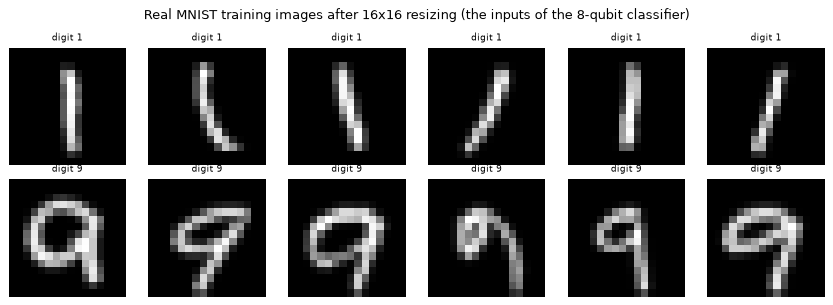

In [5]:
print("MNIST 1 vs 9:  raw 28x28 -> 16x16 = 256 pixel features per image (feature names: pixel_00 ... pixel_255, row-major)")
print("  original labels in the data: digits", sorted(set(dig_tr_all.tolist())), "-> class 0 = digit 1, class 1 = digit 9")
print("  pool: %d MNIST-train digits (1s: %d, 9s: %d) -> %d training digits drawn; validation = MNIST-test 1s and 9s: %d images (1s: %d, 9s: %d)" % (
    len(dig_tr_all), (dig_tr_all == 1).sum(), (dig_tr_all == 9).sum(), len(Xtr_m), len(Xte_m), (dig_te == 1).sum(), (dig_te == 9).sum()))
print("  training pixel range: %.2f to %.2f; amplitude vectors have unit norm" % (Xtr_m_raw.min(), Xtr_m_raw.max()))
print()
print("WDBC: 569 samples x 30 features; original labels:", dict(zip(map(str, bc.target_names), np.bincount(bc.target).tolist())))
print("  feature names:", [str(n) for n in bc.feature_names])
print("  train %d (malignant %d, benign %d), validation %d (malignant %d, benign %d); 30 min-max-scaled features zero-padded to 64 amplitudes" % (
    len(yw_tr), (yw_tr == 0).sum(), (yw_tr == 1).sum(), len(yw_te), (yw_te == 0).sum(), (yw_te == 1).sum()))

fig, ax = plt.subplots(2, 6, figsize=(10, 3.6))
for r, d in enumerate([1, 9]):
    idx = np.where(dig_tr_m == d)[0][:6]
    for j, i in enumerate(idx):
        ax[r, j].imshow(Xtr_m_raw[i].reshape(16, 16), cmap="gray"); ax[r, j].set_title(f"digit {d}", fontsize=8); ax[r, j].axis("off")
fig.suptitle("Real MNIST training images after 16x16 resizing (the inputs of the 8-qubit classifier)"); plt.tight_layout(); plt.show()

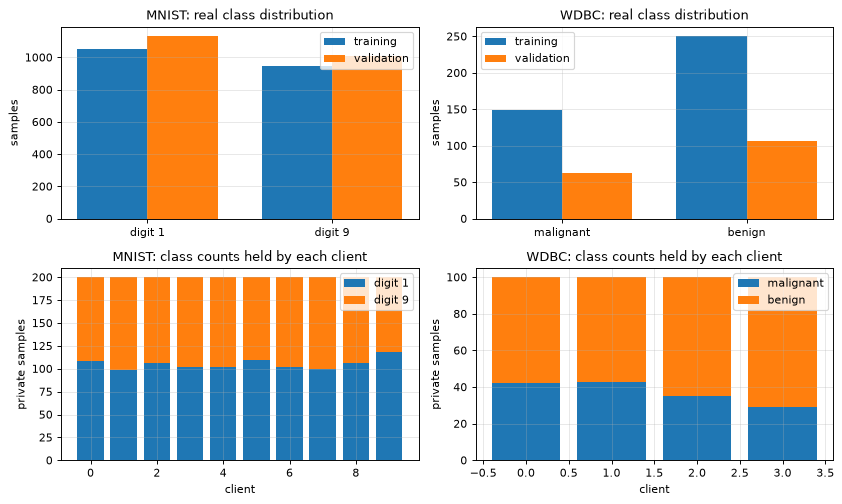

In [6]:
# Real class distributions (bar charts), and how the training pool is split among the federated clients (IID split, CHOICE)
def make_clients(X, y, n_clients, per_client, seed):
    rng = np.random.default_rng(seed); perm = rng.permutation(len(X))
    return [(X[perm[i*per_client:(i+1)*per_client]], y[perm[i*per_client:(i+1)*per_client]]) for i in range(n_clients)]
CLIENTS = {"mnist": make_clients(Xtr_m, ytr_m, DS_CFG["mnist"]["n_clients"], DS_CFG["mnist"]["per_client"], SEED),
           "wdbc":  make_clients(Xtr_w, yw_tr, DS_CFG["wdbc"]["n_clients"], DS_CFG["wdbc"]["per_client"], SEED)}

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for j, k in enumerate(["mnist", "wdbc"]):
    d = DATA[k]
    w = 0.38; xs = np.arange(2)
    ax[0, j].bar(xs - w/2, np.bincount(d["ytr"], minlength=2), w, label="training"); ax[0, j].bar(xs + w/2, np.bincount(d["yte"], minlength=2), w, label="validation")
    ax[0, j].set_xticks(xs); ax[0, j].set_xticklabels(d["names"]); ax[0, j].set_title(f"{k.upper()}: real class distribution"); ax[0, j].set_ylabel("samples"); ax[0, j].legend()
    cl = CLIENTS[k]; cnt = np.array([np.bincount(y, minlength=2) for _, y in cl])
    ax[1, j].bar(np.arange(len(cl)), cnt[:, 0], label=d["names"][0]); ax[1, j].bar(np.arange(len(cl)), cnt[:, 1], bottom=cnt[:, 0], label=d["names"][1])
    ax[1, j].set_xlabel("client"); ax[1, j].set_ylabel("private samples"); ax[1, j].set_title(f"{k.upper()}: class counts held by each client"); ax[1, j].legend()
plt.tight_layout(); plt.show()

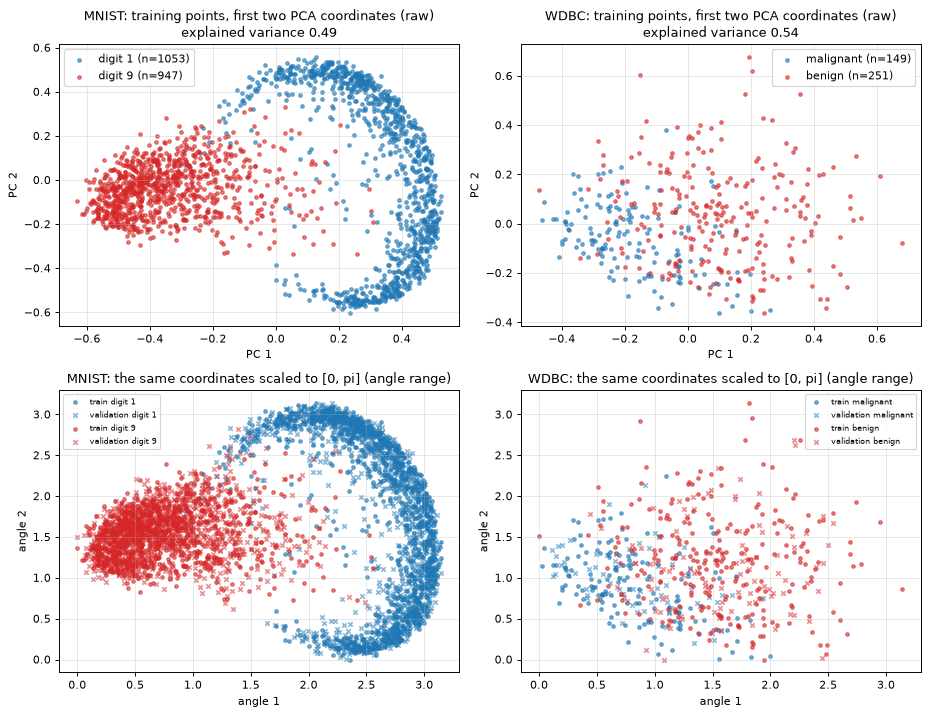

Both tasks are binary in the paper, so the 'attack family' colouring of the template reduces to the two real classes shown above.


In [7]:
# 2-D scatter of the real training observations coloured by ground-truth label (PCA fitted on the training split only)
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
cols = {0: "tab:blue", 1: "tab:red"}
for j, k in enumerate(["mnist", "wdbc"]):
    d = DATA[k]
    pca = PCA(n_components=2, random_state=SEED).fit(d["Xtr"])
    Ztr, Zte = pca.transform(d["Xtr"]), pca.transform(d["Xte"])
    for cl in (0, 1):
        m = d["ytr"] == cl
        ax[0, j].scatter(Ztr[m, 0], Ztr[m, 1], s=9, c=cols[cl], alpha=0.6, label=f"{d['names'][cl]} (n={m.sum()})")
    ax[0, j].set_title(f"{k.upper()}: training points, first two PCA coordinates (raw)\nexplained variance {pca.explained_variance_ratio_.sum():.2f}")
    ax[0, j].set_xlabel("PC 1"); ax[0, j].set_ylabel("PC 2"); ax[0, j].legend()
    mm = MinMaxScaler((0, np.pi)).fit(Ztr)
    A_tr, A_te = mm.transform(Ztr), np.clip(mm.transform(Zte), 0, np.pi)
    for cl in (0, 1):
        m = d["ytr"] == cl
        ax[1, j].scatter(A_tr[m, 0], A_tr[m, 1], s=9, c=cols[cl], alpha=0.6, label=f"train {d['names'][cl]}")
        m2 = d["yte"] == cl
        ax[1, j].scatter(A_te[m2, 0], A_te[m2, 1], s=14, c=cols[cl], alpha=0.5, marker="x", label=f"validation {d['names'][cl]}")
    ax[1, j].set_title(f"{k.upper()}: the same coordinates scaled to [0, pi] (angle range)"); ax[1, j].set_xlabel("angle 1"); ax[1, j].set_ylabel("angle 2"); ax[1, j].legend(fontsize=7)
plt.tight_layout(); plt.show()
if True:
    # multiclass note: MNIST here has only the two digit classes 1 and 9 (the paper's binary task); WDBC has benign / malignant only.
    print("Both tasks are binary in the paper, so the 'attack family' colouring of the template reduces to the two real classes shown above.")

## Quantum Circuit Architecture

The classifier of Fig. 2(a) is built twice, and the two are **asserted to be the same circuit**:

* a **PennyLane QNode** (`default.qubit`): amplitude encoding with `qml.StatePrep`, then `l = 30` repetitions of `RZ, RX, RZ` on every qubit and a layer of CNOTs, readout = probabilities of qubit 0. This is the circuit a quantum server would run, and it is the object drawn below;
* a **fast exact state-vector simulator in PyTorch** (`VQCSim`) that all training uses. A training run needs hundreds of thousands of circuit evaluations with gradients, which PennyLane's gate-by-gate simulator would take hours to do on a CPU. `VQCSim` applies each layer's single-qubit rotations as two Kronecker-product matrices and each CNOT layer as an index permutation, and gets its gradients from PyTorch autograd.

The next cells define the simulator and the QNodes, **assert that outputs and gradients agree** (the gradient of the cross-entropy loss from autograd equals the one computed with the **parameter-shift rule on the PennyLane circuit**, the method the paper names), then draw the circuits that are actually executed and print qubits, depth and trainable parameters.

Assumptions where the paper is silent (also in the table above): the order `Rz(t1)` then `Rx(t2)` then `Rz(t3)` on each qubit; the CNOT pairs `(0,1),(2,3),...` in even layers and `(1,2),(3,4),...` in odd layers (brickwork); qubit 0 is the readout; the circuit starts from the amplitude-encoded state.

In [8]:
def to_c(X):
    return torch.as_tensor(np.asarray(X), dtype=torch.complex128)

class VQCSim:
    """Exact state-vector simulator of the classifier of Fig. 2(a): l x [Rz Rx Rz on every qubit, then a CNOT layer].
    Qubit 0 is the most significant bit (PennyLane convention). theta is a flat vector of length l*n*3 ordered (layer, qubit, [Rz, Rx, Rz])."""
    def __init__(self, n, L, readout=0):
        self.n, self.L, self.dim, self.ro, self.g = n, L, 2 ** n, readout, n // 2
        idx = np.arange(self.dim); self.perms = []
        for l in range(L):
            p = idx.copy()
            for c in range(l % 2, n - 1, 2):                       # CNOT(c, c+1): flip target bit if control bit is set
                t = c + 1; cbit = (p >> (n - 1 - c)) & 1; p = p ^ (cbit << (n - 1 - t))
            self.perms.append(torch.as_tensor(p))
        bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1
        self.signs = torch.as_tensor(2.0 * bits - 1.0)             # (dim, n): +1 for bit 1, -1 for bit 0 (for a trailing Rz layer)
        self.n_params = L * n * 3
    @staticmethod
    def unitaries(th):                                              # (..., 3) -> (..., 2, 2) = Rz(c) Rx(b) Rz(a)
        a, b, c = th[..., 0], th[..., 1], th[..., 2]
        cb, sb = torch.cos(b / 2), torch.sin(b / 2); e = lambda x: torch.exp(1j * x)
        U00 = cb * e(-(a + c) / 2); U01 = -1j * sb * e((a - c) / 2); U10 = -1j * sb * e(-(a - c) / 2); U11 = cb * e((a + c) / 2)
        return torch.stack([torch.stack([U00, U01], -1), torch.stack([U10, U11], -1)], -2)
    @staticmethod
    def kron_group(U):                                              # (..., k, 2, 2) -> (..., 2^k, 2^k), Kronecker product over the qubit axis
        K = U[..., 0, :, :]
        for q in range(1, U.shape[-3]):
            K = torch.einsum("...ab,...cd->...acbd", K, U[..., q, :, :])
            K = K.reshape(*K.shape[:-4], K.shape[-4] * K.shape[-3], K.shape[-2] * K.shape[-1])
        return K
    def forward(self, psi, th, final=None):
        B, g = psi.shape[0], self.g
        U = self.unitaries(th.reshape(*th.shape[:-1], self.L, self.n, 3))
        K1 = self.kron_group(U[..., :g, :, :]); K2T = self.kron_group(U[..., g:, :, :]).transpose(-1, -2)
        for l in range(self.L):
            psi = (K1.select(-3, l) @ psi.reshape(B, 2 ** g, -1) @ K2T.select(-3, l)).reshape(B, -1)
            psi = psi[:, self.perms[l]]
        if final is not None:                                        # optional trailing Rz layer (rotation-angle encoding circuit)
            psi = psi * torch.exp(0.5j * (final @ self.signs.T))
        return psi
    def probs(self, psi, th):                                        # P(readout qubit = 0), P(= 1)
        f = self.forward(psi, th)
        return (f.real ** 2 + f.imag ** 2).reshape(f.shape[0], 2 ** self.ro, 2, -1).sum((1, 3))

def cross_entropy(P, y):
    return -torch.log(P[torch.arange(len(y)), y] + 1e-12).mean()

# ---- the real circuits (PennyLane) ----
def classifier_qnode(n, L):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def circuit(x, theta):                                           # theta: (L, n, 3)
        qml.StatePrep(x, wires=range(n))                             # amplitude encoding of the input
        for l in range(L):
            for q in range(n):
                qml.RZ(theta[l, q, 0], wires=q); qml.RX(theta[l, q, 1], wires=q); qml.RZ(theta[l, q, 2], wires=q)
            for c in range(l % 2, n - 1, 2):
                qml.CNOT(wires=[c, c + 1])
        return qml.probs(wires=0)                                    # diag of the reduced state of the readout qubit
    return circuit

def encoder_qnode(n, L):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def circuit(theta, final):                                       # rotation-angle encoding (Supplement V): input features are the angles
        for l in range(L):
            for q in range(n):
                qml.RZ(theta[l, q, 0], wires=q); qml.RX(theta[l, q, 1], wires=q); qml.RZ(theta[l, q, 2], wires=q)
            for c in range(l % 2, n - 1, 2):
                qml.CNOT(wires=[c, c + 1])
        for q in range(n): qml.RZ(final[q], wires=q)                 # the extra trailing Rz layer: 8 (3 x 11 + 1) = 272 parameters
        return qml.state()
    return circuit

SIMS = {k: VQCSim(DATA[k]["n"], N_LAYERS) for k in DATA}
QNODES = {k: classifier_qnode(DATA[k]["n"], N_LAYERS) for k in DATA}
print({k: (s.n, s.L, s.n_params) for k, s in SIMS.items()})

{'mnist': (8, 30, 720), 'wdbc': (6, 30, 540)}


In [9]:
# ---- assertion 1: simulator == PennyLane circuit (outputs), and autograd gradient == parameter-shift gradient on the PennyLane circuit ----
rng_chk = np.random.default_rng(SEED)
for k in ("mnist", "wdbc"):
    sim, qn, n = SIMS[k], QNODES[k], DATA[k]["n"]; X, y = DATA[k]["Xtr"], DATA[k]["ytr"]
    th = rng_chk.uniform(0, 2 * np.pi, sim.n_params)
    P_sim = sim.probs(to_c(X[:6]), torch.as_tensor(th)).numpy()
    P_pl = np.stack([np.asarray(qn(x, th.reshape(N_LAYERS, n, 3))) for x in X[:6]])
    e_out = np.abs(P_sim - P_pl).max()
    # gradient of the cross-entropy loss of ONE sample w.r.t. 10 random parameters
    x, lab = X[0], int(y[0]); idx = rng_chk.choice(sim.n_params, 10, replace=False)
    thT = torch.as_tensor(th).requires_grad_(True)
    g_ad = torch.autograd.grad(cross_entropy(sim.probs(to_c(x[None]), thT), torch.tensor([lab])), thT)[0].numpy()
    p0 = np.asarray(qn(x, th.reshape(N_LAYERS, n, 3)))[lab]; g_ps = []
    for j in idx:
        e = np.zeros_like(th); e[j] = np.pi / 2                     # parameter-shift rule: dg/dtheta = (g(theta + pi/2) - g(theta - pi/2)) / 2
        dp = (np.asarray(qn(x, (th + e).reshape(N_LAYERS, n, 3)))[lab] - np.asarray(qn(x, (th - e).reshape(N_LAYERS, n, 3)))[lab]) / 2
        g_ps.append(-dp / p0)                                       # chain rule of L = -log g_label
    e_grad = np.abs(np.array(g_ps) - g_ad[idx]).max()
    assert e_out < 1e-10 and e_grad < 1e-9, (k, e_out, e_grad)
    print(f"{k}: max |P_simulator - P_PennyLane| = {e_out:.1e};  max |grad_autograd - grad_parameter_shift| over 10 parameters = {e_grad:.1e}  -> equal")

mnist: max |P_simulator - P_PennyLane| = 1.5e-15;  max |grad_autograd - grad_parameter_shift| over 10 parameters = 1.4e-13  -> equal


wdbc: max |P_simulator - P_PennyLane| = 5.0e-16;  max |grad_autograd - grad_parameter_shift| over 10 parameters = 1.6e-13  -> equal


,circuit,qubits,depth,gates,trainable_parameters,note
0,MNIST classifier (8 qubits),8,121,826,720,StatePrep + 30 x (RZ RX RZ + CNOT layer); dept...
1,WDBC classifier (6 qubits),6,121,616,540,StatePrep + 30 x (RZ RX RZ + CNOT layer); dept...


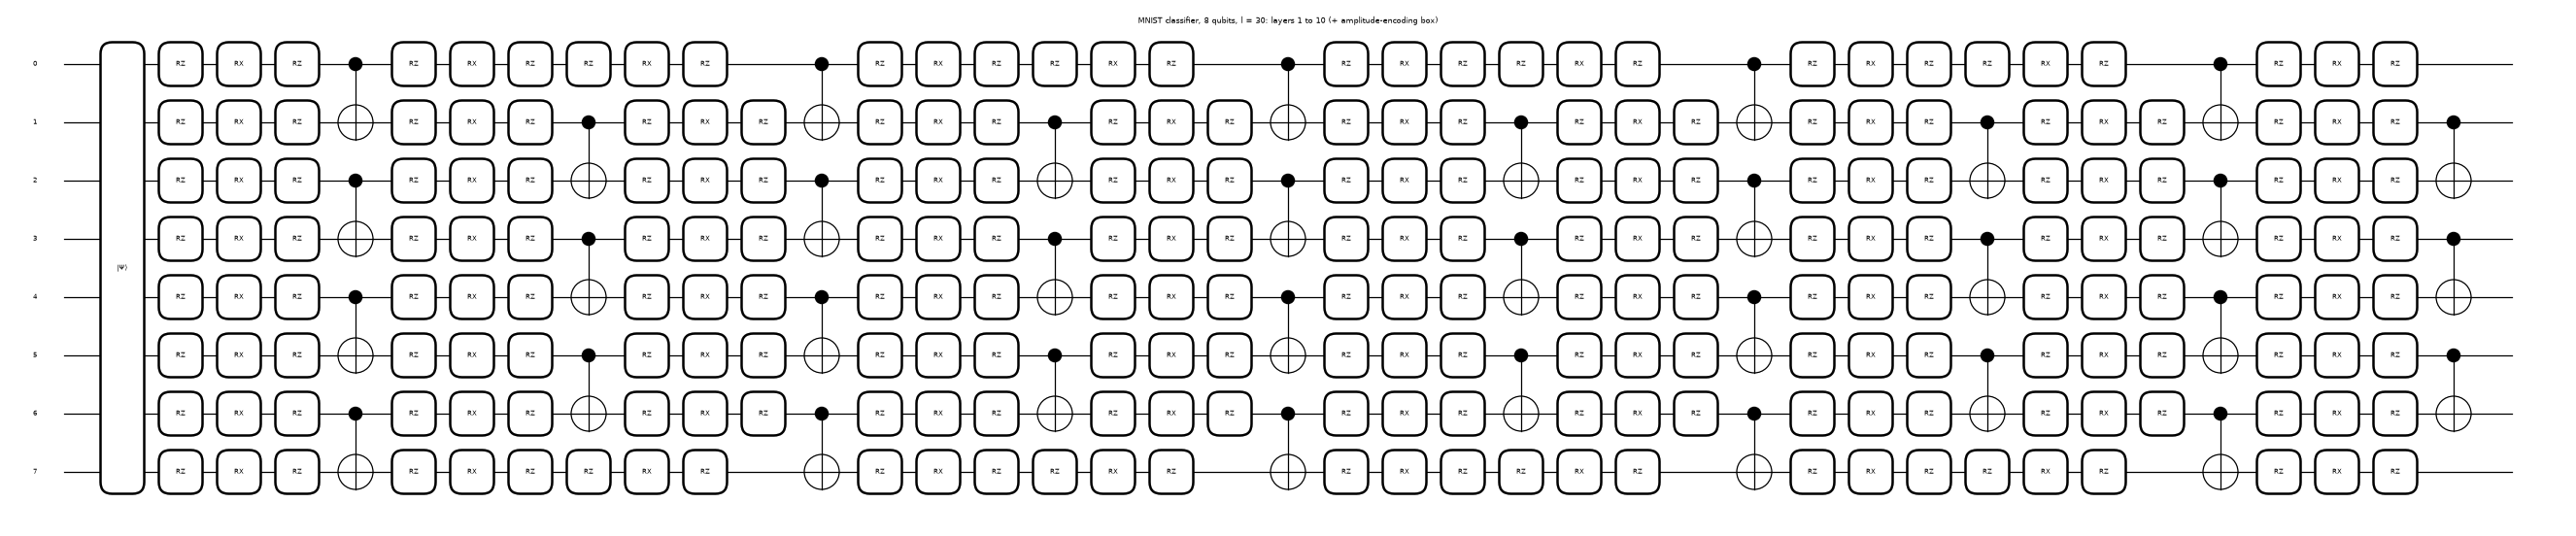

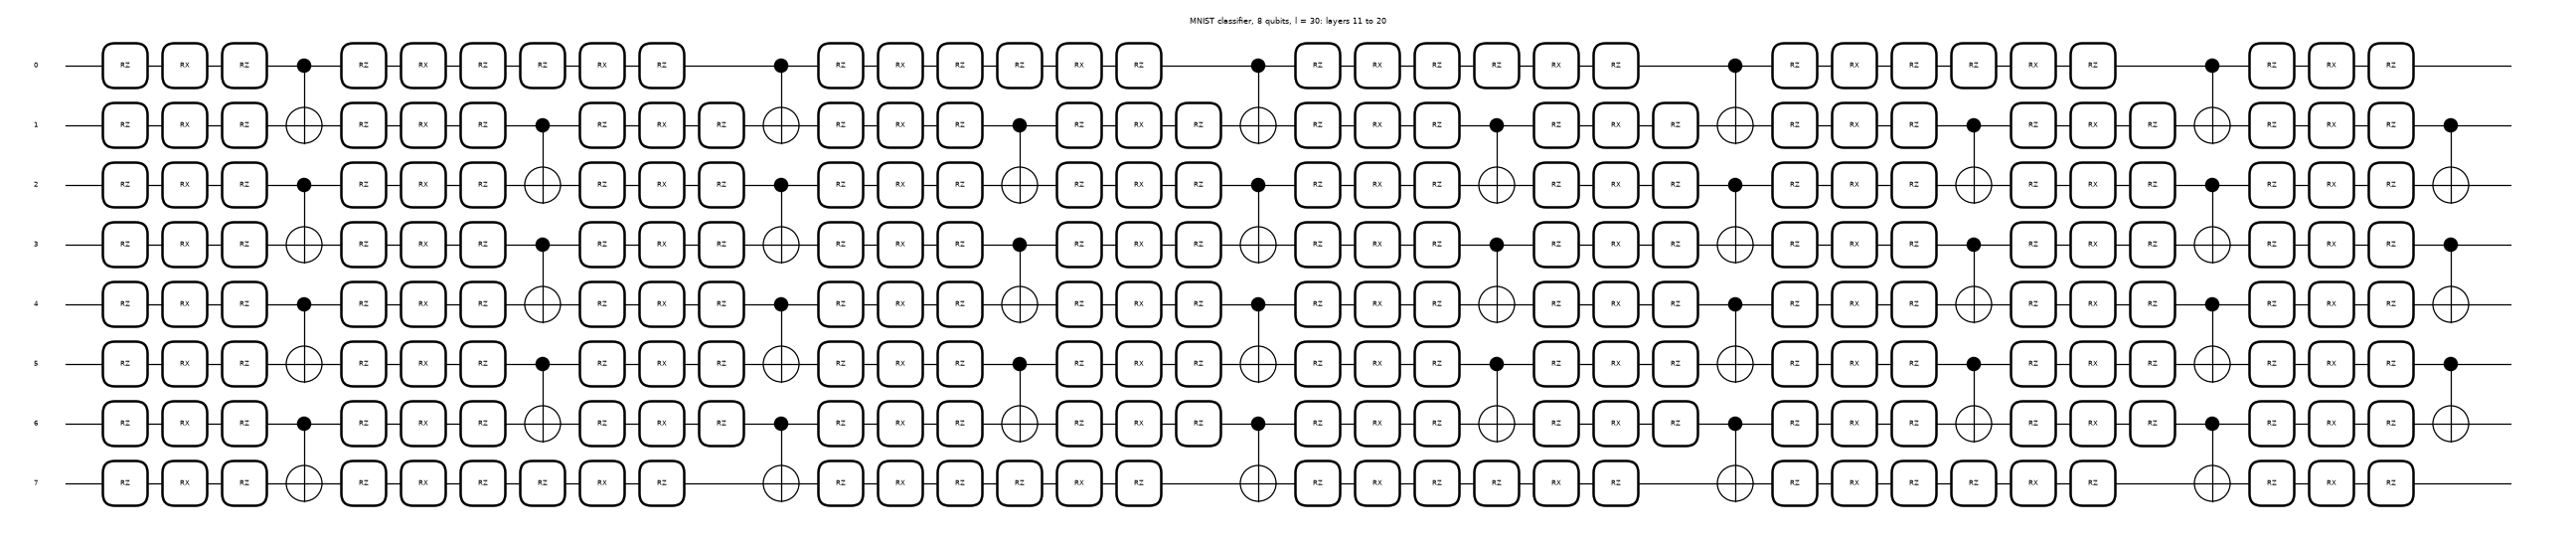

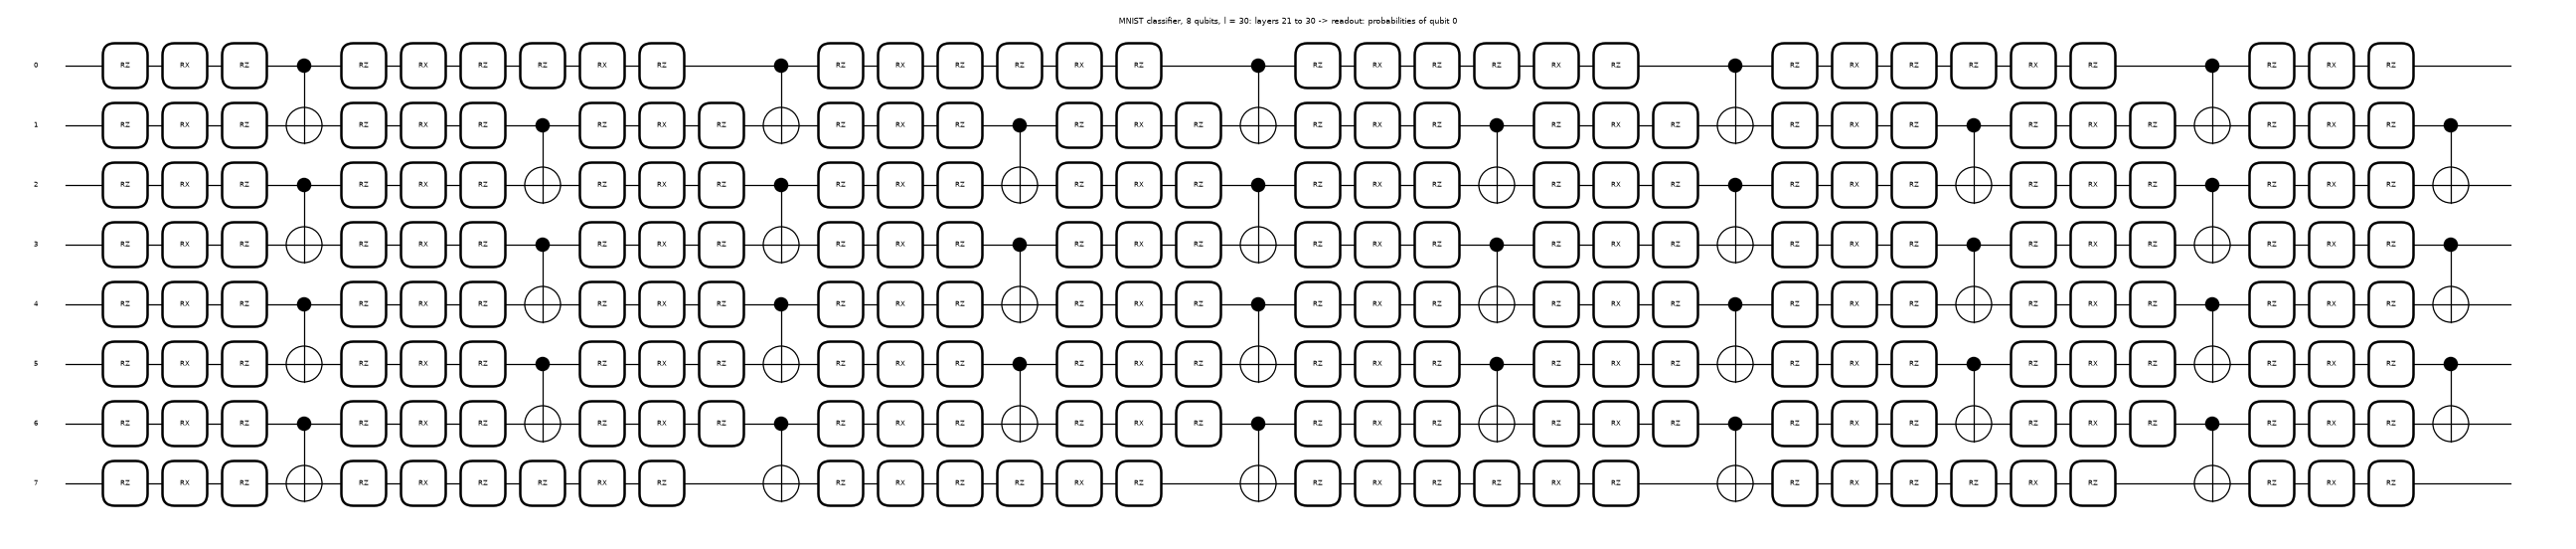

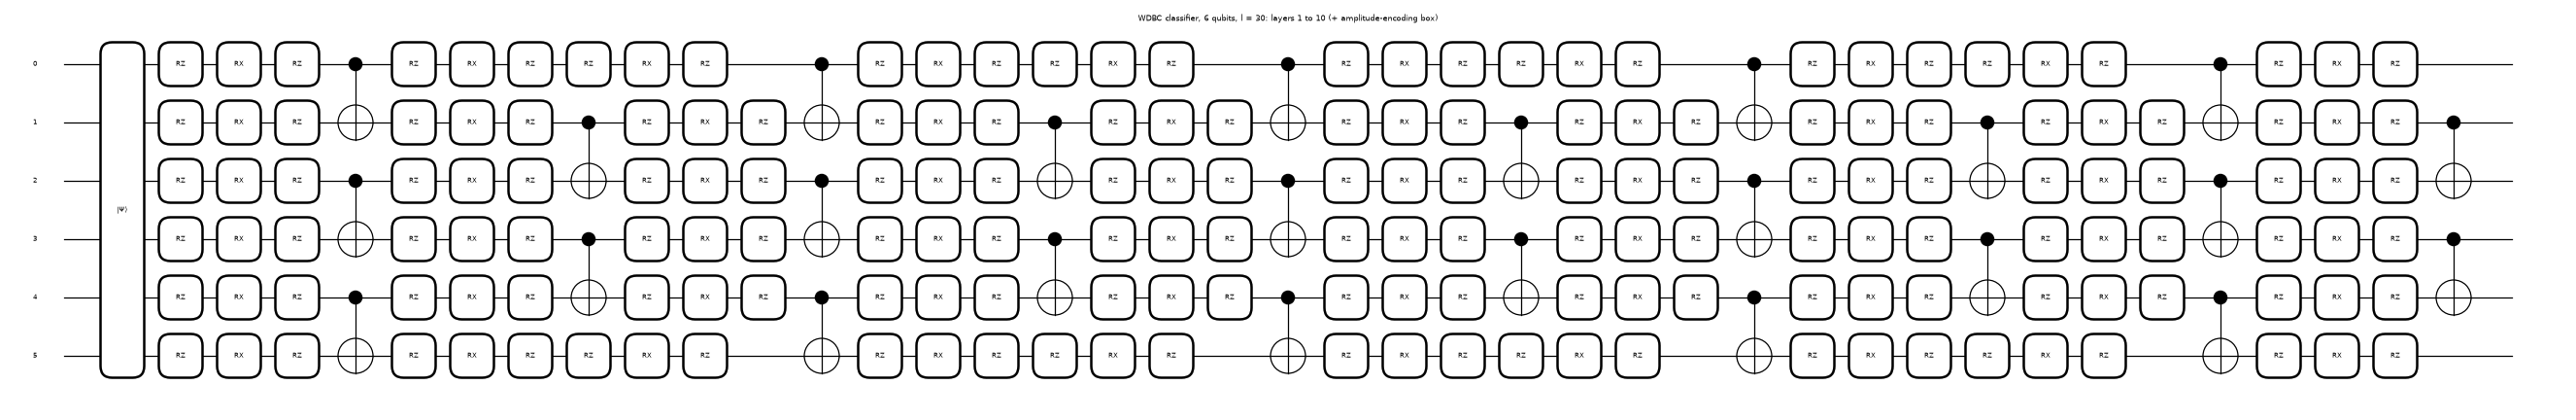

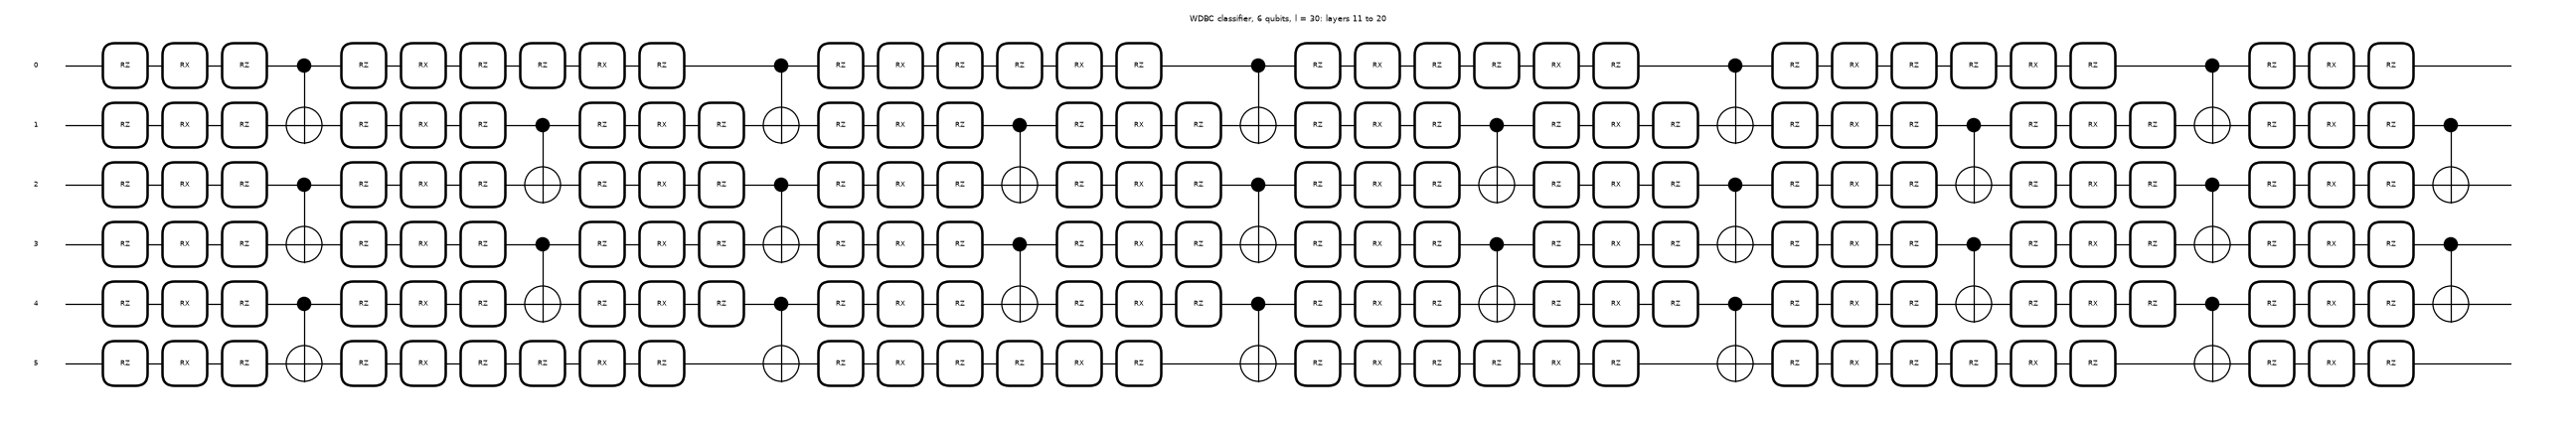

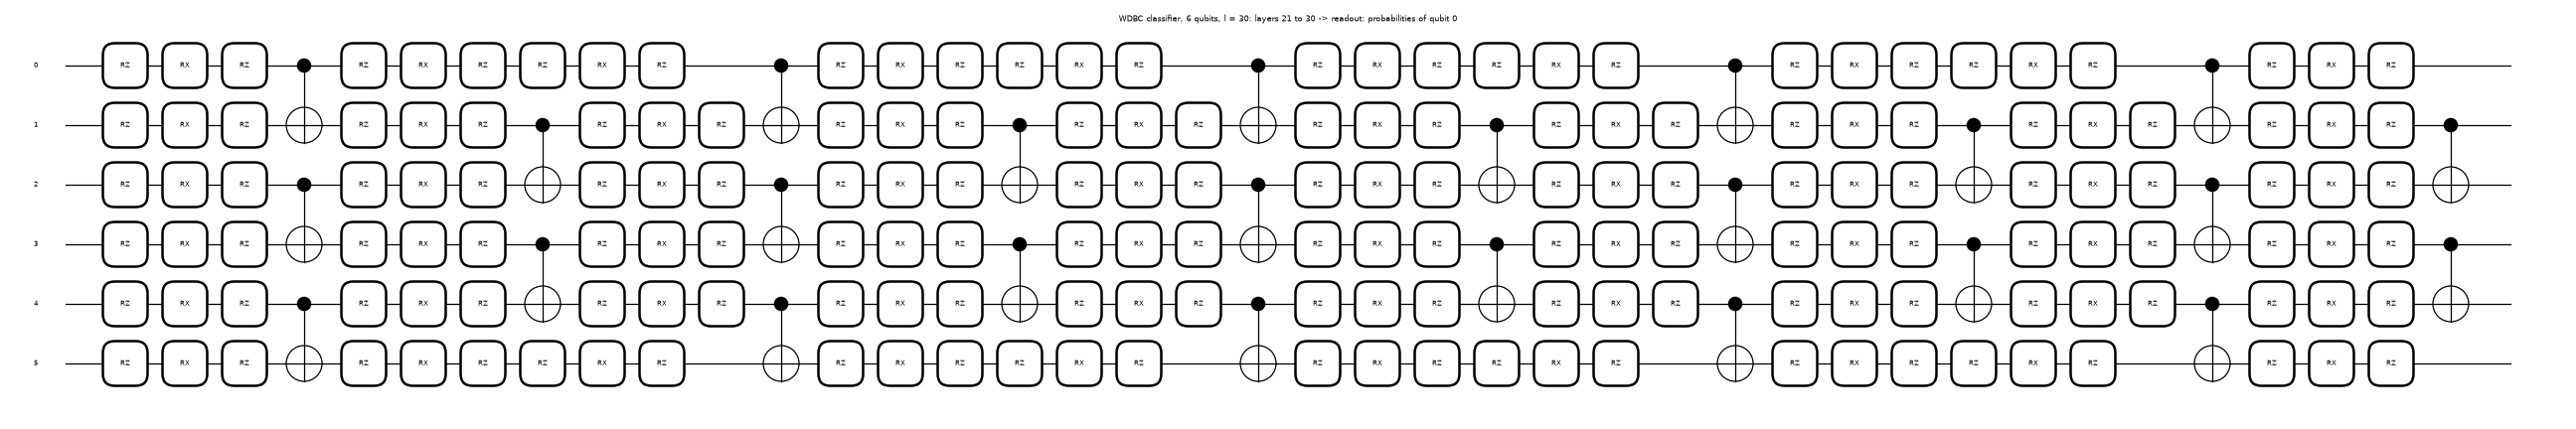

In [10]:
# ---- the circuits that are executed: draw them and print qubits / depth / trainable parameters ----
def spec_row(name, qn, args, n, n_params, note):
    s = qml.specs(qn)(*args); r = s.resources
    return dict(circuit=name, qubits=n, depth=r.depth, gates=r.num_gates, trainable_parameters=n_params, note=note)
rows = []
for k, label in (("mnist", "MNIST classifier (8 qubits)"), ("wdbc", "WDBC classifier (6 qubits)")):
    n = DATA[k]["n"]; th0 = np.zeros((N_LAYERS, n, 3)) + 0.3
    rows.append(spec_row(label, QNODES[k], (DATA[k]["Xtr"][0], th0), n, SIMS[k].n_params, "StatePrep + 30 x (RZ RX RZ + CNOT layer); depth counts the amplitude-encoding box as 1"))
display(pd.DataFrame(rows))

def draw_executed(qn, args, n, L, per_fig, title, n_pre=0):
    """Draw the operations of the QNode's own tape (the circuit that is executed), cut into rows of `per_fig` layers so that it stays readable."""
    ops = qml.workflow.construct_tape(qn)(*args).operations
    sizes = [3 * n + len(range(l % 2, n - 1, 2)) for l in range(L)]
    i, l, parts = 0, 0, []
    while l < L:
        l2 = min(L, l + per_fig); cnt = sum(sizes[l:l2]) + (n_pre if l == 0 else 0)
        take = list(ops[i:i + cnt]); i += cnt
        if l2 == L: take += list(ops[i:]); i = len(ops)
        parts.append((l, l2, take)); l = l2
    assert sum(len(t) for _, _, t in parts) == len(ops)
    for a, b, take in parts:
        fig, ax = qml.drawer.tape_mpl(qml.tape.QuantumScript(take), wire_order=list(range(n)), show_all_wires=True, decimals=None, fontsize=8)
        fig.suptitle(f"{title}: layers {a + 1} to {b}" + (" (+ amplitude-encoding box)" if a == 0 and n_pre else "") + (" -> readout: probabilities of qubit 0" if b == L else ""), fontsize=10)
        fig.set_dpi(60); plt.show()
for k, title in (("mnist", "MNIST classifier, 8 qubits, l = 30"), ("wdbc", "WDBC classifier, 6 qubits, l = 30")):
    n = DATA[k]["n"]; th0 = np.zeros((N_LAYERS, n, 3)) + 0.3
    draw_executed(QNODES[k], (DATA[k]["Xtr"][0], th0), n, N_LAYERS, 10, title, n_pre=1)   # parameter values hidden; every layer is identical in structure except the CNOT parity

encoding circuit: max |state_simulator - state_PennyLane| = 2.7e-16  -> equal; qubits 8, parameters 272
depth 45 | gates 311


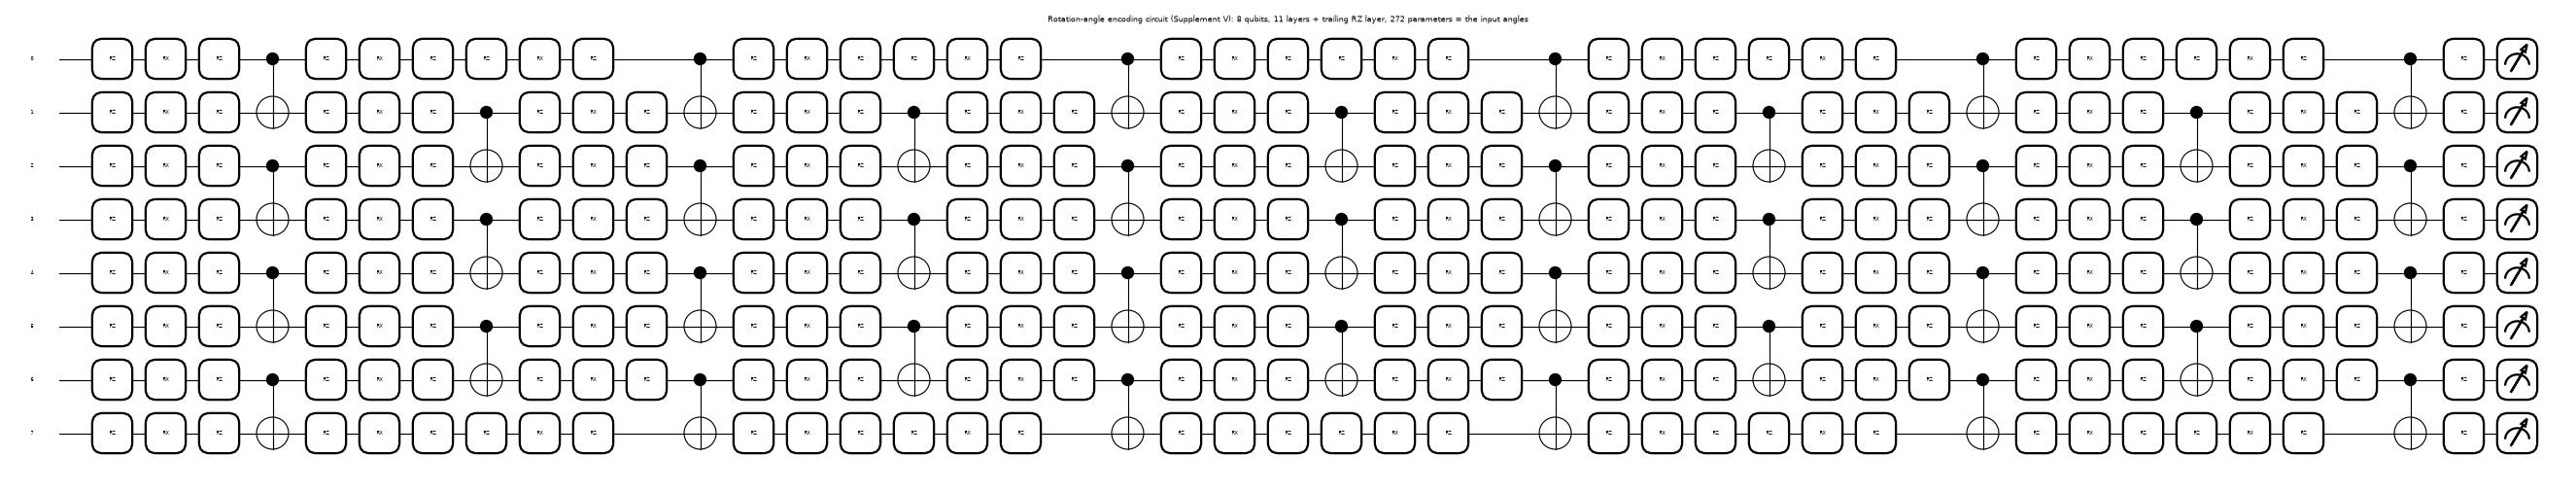

In [11]:
# ---- the rotation-angle encoding circuit of Supplement V: 8 qubits, depth 11, 8 x (3 x 11 + 1) = 272 parameters; same assertion style ----
ENC_L, ENC_N = 11, 8
enc_sim = VQCSim(ENC_N, ENC_L); enc_qn = encoder_qnode(ENC_N, ENC_L)
def encode_states(ang):
    """ang: (B, 256) feature angles -> (B, 256) complex states of the encoding circuit started from |0...0>.
    The features fill the FIRST 256 of the 272 parameters (layer-major order), the other 16 stay 0 (paper, Supplement V)."""
    ang = torch.as_tensor(ang, dtype=torch.float64); B = ang.shape[0]
    full = torch.zeros(B, ENC_L * ENC_N * 3 + ENC_N, dtype=torch.float64); full[:, :ang.shape[1]] = ang
    psi0 = torch.zeros(B, 2 ** ENC_N, dtype=torch.complex128); psi0[:, 0] = 1
    return enc_sim.forward(psi0, full[:, :-ENC_N], final=full[:, -ENC_N:])
a_test = np.random.default_rng(SEED).uniform(0, np.pi, (3, 256))
S_sim = encode_states(a_test).numpy(); S_pl = []
for a in a_test:
    full = np.zeros(272); full[:256] = a
    S_pl.append(np.asarray(enc_qn(full[:-ENC_N].reshape(ENC_L, ENC_N, 3), full[-ENC_N:])))
e_enc = np.abs(S_sim - np.stack(S_pl)).max(); assert e_enc < 1e-10, e_enc
print(f"encoding circuit: max |state_simulator - state_PennyLane| = {e_enc:.1e}  -> equal; qubits {ENC_N}, parameters {ENC_L * ENC_N * 3 + ENC_N}")
s = qml.specs(enc_qn)(np.zeros((ENC_L, ENC_N, 3)), np.zeros(ENC_N)); print("depth", s.resources.depth, "| gates", s.resources.num_gates)
fig, ax = qml.draw_mpl(enc_qn, decimals=None, fontsize=7)(np.zeros((ENC_L, ENC_N, 3)), np.zeros(ENC_N))
fig.suptitle("Rotation-angle encoding circuit (Supplement V): 8 qubits, 11 layers + trailing RZ layer, 272 parameters = the input angles", fontsize=11); fig.set_dpi(55); plt.show()

### The blind-computation protocol, and a toy instance of it

The classifier above is what the quantum server executes. **How the server is kept blind** is a protocol, not a circuit, so we simulate the protocol itself. The paper uses the brickwork state of Broadbent-Fitzsimons-Kashefi (BFK). We implement the same mechanism in the equivalent *J/CZ measurement pattern* (`# CHOICE:` it is easier to verify by simulation, and the blindness argument is identical):

* every single-qubit rotation `Rz(c) Rx(b) Rz(a)` is four measured qubits with angles `a, b, c, 0` (a chain of `J(alpha) = H P(alpha)` gates, `Rz(a) = J(0) J(a)`, `Rx(b) = J(b) J(0)`); a CNOT is `H_t CZ H_t`, so two extra measured qubits and one CZ edge; the circuit input `|0...0>` is `J(0)` applied to `|+>`;
* **client:** for every qubit the client sends `(|0> + e^{i theta}|1>)/sqrt2` with a fresh secret `theta` in `[0, 2 pi)`;
* **server:** entangles the qubits with CZ gates as the pattern says, and measures each qubit in the equatorial basis the client dictates;
* **client:** the true angle `phi` of a qubit depends on earlier outcomes (a Pauli frame). She announces `delta = phi + theta + pi r`, where `r` is a fresh secret random bit, and receives the outcome `b`; she knows the true outcome `s = b xor r` and updates her frame;
* the last qubits are returned to the client, who undoes the frame and reads out the classification qubit.

**What the server sees** is the list of `(delta_v, b_v)`. We simulate the whole exchange exactly (real qubits, real CZ, real projective measurements with sampled outcomes), for a toy instance in which **both the data and the circuit parameters travel as measurement angles**: a 2-qubit circuit with a Mottonen state-preparation circuit that loads a 4-dimensional input vector `x` (amplitude encoding), followed by two layers of the classifier. First the *correctness* is asserted against a PennyLane circuit; the statistical blindness test follows in Section 6.

In [12]:
TWO_PI = 2 * np.pi
def euler(w, a, b, c):          # Rz(c) Rx(b) Rz(a) on wire w = four J gates, in time order (a, b, c, 0)
    return [("J", w, a), ("J", w, b), ("J", w, c), ("J", w, 0.0)]
def cnot_g(c, t):               # CNOT = (I x H) CZ (I x H), H = J(0)
    return [("J", t, 0.0), ("CZ", c, t), ("J", t, 0.0)]
def ry_g(w, t):                 # Ry(t) = Rz(pi/2) Rx(t) Rz(-pi/2)
    return euler(w, -np.pi / 2, t, np.pi / 2)

def prep_angles(x):             # Mottonen angles that load the real unit vector x (4 amplitudes) into 2 qubits
    a0 = 2 * np.arctan2(np.hypot(x[2], x[3]), np.hypot(x[0], x[1]))
    b0 = 2 * np.arctan2(x[1], x[0]); b1 = 2 * np.arctan2(x[3], x[2])
    return a0, (b0 + b1) / 2, (b0 - b1) / 2

def toy_gate_list(x, theta):    # the whole delegated computation as a list of J / CZ steps: data loading + classifier layers
    a0, a1, a2 = prep_angles(x)
    g = [("J", 0, 0.0), ("J", 1, 0.0)]                               # |+> -> |0> on both wires
    g += ry_g(0, a0) + ry_g(1, a1) + cnot_g(0, 1) + ry_g(1, a2) + cnot_g(0, 1)
    for l in range(theta.shape[0]):
        for w in range(2): g += euler(w, *theta[l, w])
        g += cnot_g(0, 1)
    return g

def toy_qnode(L):               # the same computation as an ordinary circuit
    dev = qml.device("default.qubit", wires=2)
    @qml.qnode(dev)
    def circuit(x, theta):
        a0, a1, a2 = prep_angles(x)
        qml.RY(a0, wires=0); qml.RY(a1, wires=1); qml.CNOT(wires=[0, 1]); qml.RY(a2, wires=1); qml.CNOT(wires=[0, 1])
        for l in range(theta.shape[0]):
            for w in range(2):
                qml.RZ(theta[l, w, 0], wires=w); qml.RX(theta[l, w, 1], wires=w); qml.RZ(theta[l, w, 2], wires=w)
            qml.CNOT(wires=[0, 1])
        return qml.probs(wires=0)
    return circuit

def run_ubqc(gates, n_wires, readout, R, rng, blind=True):
    """Exact simulation of R independent runs of the blind protocol. Returns the server's transcript (delta, b) of shape (R, #measured qubits)
    and the client's decoded output probabilities (R, 2). blind=False switches the secrets off (theta = 0, r = 0): the unprotected control."""
    th = rng.uniform(0, TWO_PI, (n_wires, R)) if blind else np.zeros((n_wires, R))
    psi, axes = None, []
    for w in range(n_wires):                                          # client sends P(theta)|+> for the first node of every wire
        q = np.stack([np.ones(R), np.exp(1j * th[w])], -1) / np.sqrt(2)
        psi = q if psi is None else psi[..., None] * q.reshape((R,) + (1,) * (psi.ndim - 1) + (2,)); axes.append(w)
    fx = np.zeros((n_wires, R), int); fz = np.zeros((n_wires, R), int)    # the client's Pauli frame X^x Z^z per wire
    deltas, bits = [], []
    for g in gates:
        if g[0] == "CZ":
            _, a, b = g
            sl = [slice(None)] * psi.ndim; sl[axes.index(a) + 1] = 1; sl[axes.index(b) + 1] = 1; psi[tuple(sl)] *= -1
            xa, xb = fx[a].copy(), fx[b].copy(); fz[a] ^= xb; fz[b] ^= xa
            continue
        _, w, alpha = g
        th_new = rng.uniform(0, TWO_PI, R) if blind else np.zeros(R)  # 1. client sends the next node; the server entangles it (CZ) with the old one
        q = np.stack([np.ones(R), np.exp(1j * th_new)], -1) / np.sqrt(2)
        psi = psi[..., None] * q.reshape((R,) + (1,) * (psi.ndim - 1) + (2,))
        ao = axes.index(w) + 1
        sl = [slice(None)] * psi.ndim; sl[ao] = 1; sl[-1] = 1; psi[tuple(sl)] *= -1
        phi = -np.where(fx[w] == 1, -alpha, alpha)                    # 2. true angle (frame corrected), then hidden: delta = phi + theta + pi r
        r = rng.integers(0, 2, R) if blind else np.zeros(R, int)
        delta = (phi + th[w] + np.pi * r) % TWO_PI
        p0_, p1_ = np.take(psi, 0, axis=ao), np.take(psi, 1, axis=ao)  # 3. the server measures the old node in basis (|0> +- e^{i delta}|1>)/sqrt2
        ph = np.exp(-1j * delta).reshape((R,) + (1,) * (p0_.ndim - 1))
        e0, e1 = (p0_ + ph * p1_) / np.sqrt(2), (p0_ - ph * p1_) / np.sqrt(2)
        pr0 = (np.abs(e0) ** 2).reshape(R, -1).sum(1)
        b = (rng.random(R) >= pr0).astype(int)                        # reported outcome (sampled with the Born probabilities)
        shp = (R,) + (1,) * (e0.ndim - 1)
        psi = np.where(b.reshape(shp) == 0, e0, e1) / np.sqrt(np.where(b == 0, pr0, 1 - pr0)).reshape(shp)
        axes.pop(ao - 1); axes.append(w)
        s = b ^ r                                                     # 4. client: true outcome, frame update
        fx_old, fz_old = fx[w].copy(), fz[w].copy(); fx[w] = s ^ fz_old; fz[w] = fx_old
        th[w] = th_new; deltas.append(delta); bits.append(b)
    ax = axes.index(readout) + 1                                      # returned qubit: the client removes her frame (an X flips the Z-basis bit)
    pr = np.moveaxis(np.abs(psi) ** 2, ax, 1).reshape(R, 2, -1).sum(-1)
    return np.array(deltas).T, np.array(bits).T, np.where(fx[readout][:, None] == 1, pr[:, ::-1], pr)

# toy instance: 2 qubits, 4 amplitudes, l = 2 classifier layers
L_TOY = 2
rng_toy = np.random.default_rng(SEED)
def random_unit(rng): v = rng.normal(size=4); return v / np.linalg.norm(v)
X_A, X_B = random_unit(rng_toy), random_unit(rng_toy)
TH_A, TH_B = rng_toy.uniform(0, TWO_PI, (L_TOY, 2, 3)), rng_toy.uniform(0, TWO_PI, (L_TOY, 2, 3))
toy_qn = toy_qnode(L_TOY)
# the state-preparation circuit really loads x
dev2 = qml.device("default.qubit", wires=2)
@qml.qnode(dev2)
def prep_state(x):
    a0, a1, a2 = prep_angles(x); qml.RY(a0, wires=0); qml.RY(a1, wires=1); qml.CNOT(wires=[0, 1]); qml.RY(a2, wires=1); qml.CNOT(wires=[0, 1]); return qml.state()
assert np.allclose(np.abs(np.vdot(prep_state(X_A), X_A)), 1, atol=1e-12), "Mottonen preparation does not load x"
for name, x, th in (("A", X_A, TH_A), ("B", X_B, TH_B)):
    gl = toy_gate_list(x, th); n_meas = sum(1 for g in gl if g[0] == "J")
    ideal = np.asarray(toy_qn(x, th))
    _, _, p_blind = run_ubqc(gl, 2, 0, 300, rng_toy, blind=True)
    _, _, p_plain = run_ubqc(gl, 2, 0, 50, rng_toy, blind=False)
    e1, e2 = np.abs(p_blind - ideal).max(), np.abs(p_plain - ideal).max()
    assert e1 < 1e-9 and e2 < 1e-9, (e1, e2)
    print(f"computation {name}: {n_meas} measured qubits; ideal P = {np.round(ideal, 6)}; max deviation of the client's decoded P over 300 blind runs: {e1:.1e} (unprotected control: {e2:.1e})  -> correct")

computation A: 38 measured qubits; ideal P = [0.404869 0.595131]; max deviation of the client's decoded P over 300 blind runs: 3.4e-13 (unprotected control: 1.9e-14)  -> correct
computation B: 38 measured qubits; ideal P = [0.172556 0.827444]; max deviation of the client's decoded P over 300 blind runs: 5.4e-13 (unprotected control: 3.2e-14)  -> correct


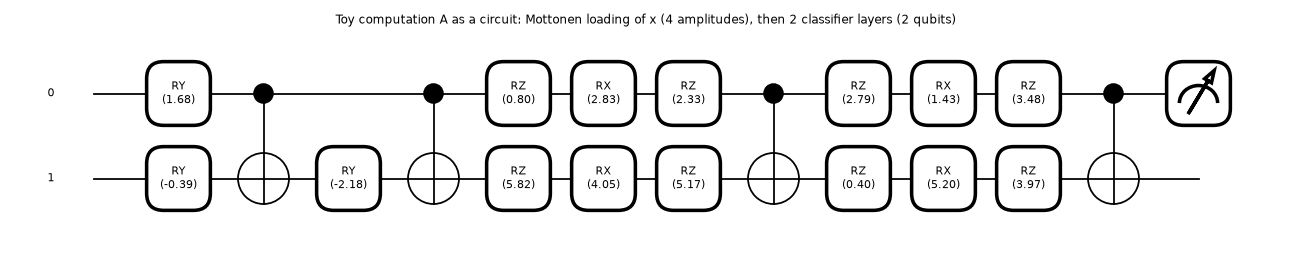

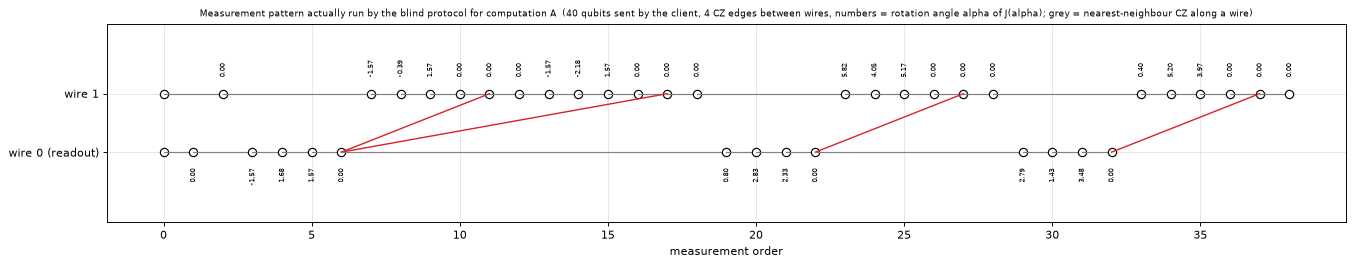

toy computation: qubits on the server 40, entangling CZ between wires 4, client-held trainable angles 12, data angles 3


In [13]:
# Drawing of the executed toy computation: (a) the circuit as an ordinary QNode, (b) the measurement pattern that the protocol runs,
# generated from the SAME gate list that run_ubqc executes (the assertion above shows that this gate list reproduces the QNode output).
fig, ax = qml.draw_mpl(toy_qn, decimals=2, fontsize=9)(X_A, TH_A); fig.suptitle("Toy computation A as a circuit: Mottonen loading of x (4 amplitudes), then 2 classifier layers (2 qubits)", fontsize=10); plt.show()

def draw_pattern(gates, title):
    fig, ax = plt.subplots(figsize=(16, 3.2)); col = 0; cur = {0: (0, 0), 1: (0, 1)}   # wire -> (column, row) of its current node
    for w in (0, 1): ax.plot([0], [w], "o", c="k", ms=7, mfc="w")
    n_nodes = 2; n_cz = 0
    for g in gates:
        if g[0] == "CZ":
            (c0, y0), (c1, y1) = cur[g[1]], cur[g[2]]
            ax.plot([c0, c1], [y0, y1], "-", c="tab:red", lw=1.2); n_cz += 1; continue
        _, w, alpha = g; col += 1
        ax.plot([cur[w][0], col], [w, w], "-", c="0.5", lw=1); ax.plot([col], [w], "o", c="k", ms=7, mfc="w"); n_nodes += 1
        ax.text(col, w - 0.28 if w == 0 else w + 0.28, f"{alpha:.2f}", rotation=90, fontsize=6, ha="center", va="top" if w == 0 else "bottom")
        cur[w] = (col, w)
    ax.set_ylim(-1.2, 2.2); ax.set_yticks([0, 1]); ax.set_yticklabels(["wire 0 (readout)", "wire 1"]); ax.set_xlabel("measurement order")
    ax.set_title(title + f"  ({n_nodes} qubits sent by the client, {n_cz} CZ edges between wires, numbers = rotation angle alpha of J(alpha); grey = nearest-neighbour CZ along a wire)", fontsize=8); plt.tight_layout(); plt.show()
    return n_nodes, n_cz
n_nodes, n_cz = draw_pattern(toy_gate_list(X_A, TH_A), "Measurement pattern actually run by the blind protocol for computation A")
print(f"toy computation: qubits on the server {n_nodes}, entangling CZ between wires {n_cz}, client-held trainable angles {TH_A.size}, data angles 3")

## 2. Training machinery: the paper's Algorithm 1 for any model

One function, `train`, implements the loop of Algorithm 1 and is used for **every** model, quantum and classical, so that the classical baselines are trained under exactly the same protocol:

1. draw a random string `S` of client indices (one per iteration);
2. the chosen client draws `n_b` of its private samples and computes the mini-batch gradient of the cross entropy (for the quantum model this is the part delegated to the blind quantum server; its result is exactly the parameter-shift gradient, asserted above);
3. **clip** every gradient element to `[-R, R]` (`g / max(1, |g|/R)`), **add** `N(0,1) x 2R/mu` to every element;
4. the shared parameters are updated with Adam.

With a single client and no `R`, `mu` this is the single-party delegated training. Data of different clients never mix: each client only ever contributes a clipped, noisy gradient. The models are the quantum classifier (`QModel`), a softmax logistic regression (`LinearModel`) and a one-hidden-layer tanh MLP (`MLPModel`), all on the same unit-norm input vectors.

In [14]:
class QModel:
    """Variational quantum classifier: parameters = the 30 x n x 3 circuit angles; gradient = exact (autograd == parameter shift, asserted above)."""
    name = "quantum VQC"
    def __init__(self, sim): self.sim = sim; self.n_params = sim.n_params
    def init(self, seed):                                              # CHOICE: uniform in [0, 2 pi)
        return torch.rand(self.n_params, generator=torch.Generator().manual_seed(seed), dtype=torch.float64) * TWO_PI
    def loss_grad(self, w, X, y):
        w = w.clone().requires_grad_(True)
        loss = cross_entropy(self.sim.probs(to_c(X), w), torch.as_tensor(y))
        return loss.item(), torch.autograd.grad(loss, w)[0]
    def evaluate(self, w, X, y):
        with torch.no_grad():
            P = self.sim.probs(to_c(X), w); yt = torch.as_tensor(y)
            return (P.argmax(1) == yt).double().mean().item(), cross_entropy(P, yt).item()

class _Classical:
    def loss_grad(self, w, X, y):
        w = w.clone().requires_grad_(True); loss = torch.nn.functional.cross_entropy(self.logits(w, torch.as_tensor(X)), torch.as_tensor(y))
        return loss.item(), torch.autograd.grad(loss, w)[0]
    def evaluate(self, w, X, y):
        with torch.no_grad():
            Z = self.logits(w, torch.as_tensor(X)); yt = torch.as_tensor(y)
            return (Z.argmax(1) == yt).double().mean().item(), torch.nn.functional.cross_entropy(Z, yt).item()

class LinearModel(_Classical):
    """Softmax logistic regression on the same unit vectors: 2d + 2 parameters."""
    name = "logistic regression"
    def __init__(self, d): self.d = d; self.n_params = 2 * d + 2
    def init(self, seed): return 0.1 * torch.randn(self.n_params, generator=torch.Generator().manual_seed(seed), dtype=torch.float64)
    def logits(self, w, X): return X @ w[:2 * self.d].reshape(2, self.d).T + w[2 * self.d:]

class MLPModel(_Classical):
    """One hidden tanh layer (h units); comparable parameter count to the 540 / 720-parameter circuits (h = 3 -> 777 for d = 256, h = 8 -> 538 for d = 64)."""
    name = "MLP"
    def __init__(self, d, h): self.d, self.h = d, h; self.n_params = d * h + h + h * 2 + 2
    def init(self, seed): return 0.3 * torch.randn(self.n_params, generator=torch.Generator().manual_seed(seed), dtype=torch.float64)
    def logits(self, w, X):
        d, h = self.d, self.h
        W1 = w[:d * h].reshape(h, d); b1 = w[d * h:d * h + h]; W2 = w[d * h + h:d * h + h + 2 * h].reshape(2, h); b2 = w[-2:]
        return torch.tanh(X @ W1.T + b1) @ W2.T + b2

MODELS = {"mnist": {"quantum": QModel(SIMS["mnist"]), "logreg": LinearModel(256), "mlp": MLPModel(256, 3)},
          "wdbc":  {"quantum": QModel(SIMS["wdbc"]),  "logreg": LinearModel(64),  "mlp": MLPModel(64, 8)}}

def noisy(X, s, rng):                                                  # input noise of the robustness test: N(0, s^2) on every element, re-normalised
    Z = X + s * rng.normal(size=X.shape); return Z / np.linalg.norm(Z, axis=1, keepdims=True)

def train(model, w0, clients, ev, T, lr, nb, seed, R=None, mu=None, mu_clients=None, in_noise=0.0, g_noise=0.0,
          eval_every=20, ckpt_at=()):
    """Algorithm 1. ev = dict(Xtr, ytr, Xva, yva) fixed evaluation subsets. Returns the history and the final parameters."""
    rng = np.random.default_rng(seed)
    w = w0.clone().requires_grad_(True); opt = torch.optim.Adam([w], lr=lr)
    S = rng.integers(0, len(clients), T)                                # the random client string S of Algorithm 1
    H = dict(it=[], tr_acc=[], tr_loss=[], va_acc=[], va_loss=[]); ck = {}; t0 = time.time()
    for t in range(T):
        Xc, yc = clients[S[t]]
        idx = rng.choice(len(Xc), min(nb, len(Xc)), replace=False)
        Xb = noisy(Xc[idx], in_noise, rng) if in_noise else Xc[idx]
        _, g = model.loss_grad(w.detach(), Xb, yc[idx])                  # <- the delegated (blind) gradient computation
        if g_noise: g = g + g_noise * torch.as_tensor(rng.normal(size=g.shape))
        if R is not None:
            g = g.clamp(-R, R)                                           # g / max(1, |g|/R) for every element
            m = mu if mu_clients is None else mu_clients[S[t]]
            if m: g = g + (2 * R / m) * torch.as_tensor(rng.normal(size=g.shape))
        w.grad = g; opt.step()
        if t + 1 in ckpt_at: ck[t + 1] = w.detach().clone()
        if t == 0 or (t + 1) % eval_every == 0 or t == T - 1:
            Xv = noisy(ev["Xva"], in_noise, np.random.default_rng(seed + 1000 + t)) if in_noise else ev["Xva"]
            a1, l1 = model.evaluate(w.detach(), ev["Xtr"], ev["ytr"]); a2, l2 = model.evaluate(w.detach(), Xv, ev["yva"])
            for k, v in zip(H, (t + 1, a1, l1, a2, l2)): H[k].append(v)
    H = {k: np.array(v) for k, v in H.items()}
    H["w"] = w.detach().clone(); H["ckpt"] = ck; H["seconds"] = time.time() - t0
    return H

def eval_sets(ds, seed=SEED):
    d = DATA[ds]; r = np.random.default_rng(seed); k = SCALE["n_eval"]
    i1 = r.choice(len(d["Xtr"]), min(k, len(d["Xtr"])), replace=False); i2 = r.choice(len(d["Xte"]), min(k, len(d["Xte"])), replace=False)
    return dict(Xtr=d["Xtr"][i1], ytr=d["ytr"][i1], Xva=d["Xte"][i2], yva=d["yte"][i2])
EV = {ds: eval_sets(ds) for ds in DATA}
SEEDS = [SEED + i for i in range(SCALE["seeds"])]
RUNS = {}                                                                # (dataset, model, mode, tag, seed) -> history

def run(ds, mk, mode, seed, tag="", T=None, lr=LR, **kw):
    c = DS_CFG[ds]; model = MODELS[ds][mk]
    if mode == "single":
        clients = [(DATA[ds]["Xtr"], DATA[ds]["ytr"])]; T = T or c["T_single"]; nb = c["nb_single"]; extra = {}
    else:
        clients = CLIENTS[ds]; T = T or c["T_fed"]; nb = c["nb_fed"]; extra = dict(R=R_CLIP, mu=kw.pop("mu", None))
    extra.update(kw)
    key = (ds, mk, mode, tag, seed)
    RUNS[key] = train(model, model.init(seed), clients, EV[ds], T, lr, nb, seed, eval_every=SCALE["eval_every"], **extra)
    return RUNS[key]

def final_metrics(ds, mk, H):                                             # full validation set, last iterate (no best-checkpoint selection)
    return MODELS[ds][mk].evaluate(H["w"], DATA[ds]["Xte"], DATA[ds]["yte"])

def first_reach(H, thr=0.9):                                              # first iteration at which the validation accuracy (subset) reaches thr
    i = np.where(H["va_acc"] >= thr)[0]; return int(H["it"][i[0]]) if len(i) else None

## 3. Experiment 1: single-party delegated training (Fig. 3a,b) and the federated protocol with differential privacy (Fig. 3c,d)

Single party: the client holds all 2000 (MNIST) or 400 (WDBC) training samples, batch 50 or 100, `T = 300` Adam steps, no clipping and no noise (the paper's privacy argument is the UBQC protocol, not DP). Federated: 10 (MNIST) or 4 (WDBC) clients with 200 or 100 private samples each, batch 50, `T = 1500` or `1000` steps, clipping `R = 0.01`, DP noise `mu = 1`. The curves are the accuracy and loss on a fixed random subset of the training pool ("training") and of the held-out set ("validation"); the numbers in the table are measured on the **whole** held-out set at the last iteration.

mnist done 976 s


wdbc done 1217 s


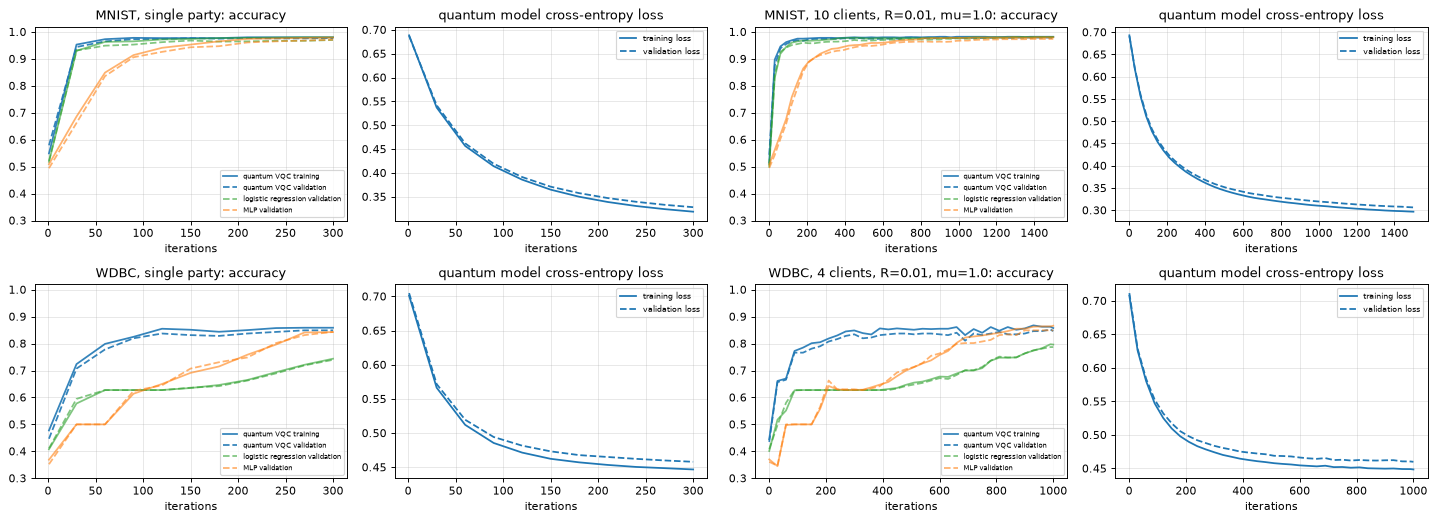

In [15]:
t_start = time.time()
for ds in ("mnist", "wdbc"):
    for seed in SEEDS:
        for mk in ("quantum", "logreg", "mlp"):
            run(ds, mk, "single", seed)
            run(ds, mk, "fed", seed, tag=f"mu{MU_MAIN}", mu=MU_MAIN)
        for mk in ("logreg", "mlp"):                                   # extra classical rows: the same protocol with a 50x larger Adam step (0.05, a single untuned alternative)
            run(ds, mk, "single", seed, tag="lr0.05", lr=0.05)
            run(ds, mk, "fed", seed, tag=f"mu{MU_MAIN}_lr0.05", mu=MU_MAIN, lr=0.05)
    print(ds, "done", round(time.time() - t_start), "s")

def fig3_panel(ds):
    fig, ax = plt.subplots(2, 4, figsize=(17, 6.2))
    for r, ds_ in enumerate(ds):
        for j, (mode, tag) in enumerate((("single", ""), ("fed", f"mu{MU_MAIN}"))):
            a_acc, a_loss = ax[r, 2 * j], ax[r, 2 * j + 1]
            for mk, col in (("quantum", "tab:blue"), ("logreg", "tab:green"), ("mlp", "tab:orange")):
                Hs = [RUNS[(ds_, mk, mode, tag, s)] for s in SEEDS]; it = Hs[0]["it"]
                for key, ls, lab in (("tr_acc", "-", "training"), ("va_acc", "--", "validation")):
                    a_acc.plot(it, np.mean([h[key] for h in Hs], 0), ls, c=col, label=f"{MODELS[ds_][mk].name} {lab}" if mk == "quantum" or key == "va_acc" else None, alpha=0.9 if mk == "quantum" else 0.6)
                if mk == "quantum":
                    for key, ls, lab in (("tr_loss", "-", "training loss"), ("va_loss", "--", "validation loss")):
                        a_loss.plot(it, np.mean([h[key] for h in Hs], 0), ls, c=col, label=lab)
            ttl = ("single party" if mode == "single" else f"{DS_CFG[ds_]['n_clients']} clients, R={R_CLIP}, mu={MU_MAIN}")
            a_acc.set_title(f"{ds_.upper()}, {ttl}: accuracy"); a_acc.set_xlabel("iterations"); a_acc.set_ylim(0.3, 1.02); a_acc.legend(fontsize=6, loc="lower right")
            a_loss.set_title("quantum model cross-entropy loss"); a_loss.set_xlabel("iterations"); a_loss.legend(fontsize=7)
    plt.tight_layout(); plt.show()
fig3_panel(["mnist", "wdbc"])

In [16]:
# Final numbers on the WHOLE validation set (last iterate), mean +- std over seeds; classical rows = same Algorithm 1, same inputs
def ms(v): return f"{100 * np.mean(v):.2f} +- {100 * np.std(v):.2f}" if len(v) > 1 else f"{100 * v[0]:.2f}"
rows = []
for ds in ("mnist", "wdbc"):
    for mode, tag in (("single", ""), ("fed", f"mu{MU_MAIN}")):
        for mk, suffix in (("quantum", ""), ("logreg", ""), ("mlp", ""), ("logreg", "_lr0.05"), ("mlp", "_lr0.05")):
            tg = (tag + suffix) if mode == "fed" else (("lr0.05") if suffix else "")
            acc = [final_metrics(ds, mk, RUNS[(ds, mk, mode, tg, s)])[0] for s in SEEDS]
            sec = np.mean([RUNS[(ds, mk, mode, tg, s)]["seconds"] for s in SEEDS])
            rows.append(dict(dataset=ds, protocol=("single party" if mode == "single" else f"federated DP mu={MU_MAIN}"), model=MODELS[ds][mk].name + (" (Adam lr 0.05)" if suffix else ""),
                             params=MODELS[ds][mk].n_params, final_val_acc_pct=ms(acc), iterations_to_90pct=[first_reach(RUNS[(ds, mk, mode, tg, s)]) for s in SEEDS], train_seconds=round(sec, 1)))
TAB1 = pd.DataFrame(rows); display(TAB1)

# centralised classical reference on the SAME inputs (pooled training data, no federated protocol, no privacy)
ref = []
for ds in ("mnist", "wdbc"):
    d = DATA[ds]
    for name, clf in (("RandomForest(300)", RandomForestClassifier(300, random_state=SEED)), ("SVC(rbf)", SVC(kernel="rbf", C=1.0)), ("LogisticRegression", LogisticRegression(C=10, max_iter=2000))):
        a = clf.fit(d["Xtr"], d["ytr"]).score(d["Xte"], d["yte"]); ref.append(dict(dataset=ds, classifier=name + " (centralised, scikit-learn)", val_acc_pct=round(100 * a, 2)))
REF = pd.DataFrame(ref); display(REF)

,dataset,protocol,model,params,final_val_acc_pct,iterations_to_90pct,train_seconds
0,mnist,single party,quantum VQC,720,98.55 +- 0.05,"[30, 30]",69.5
1,mnist,single party,logistic regression,514,98.02 +- 0.30,"[30, 30]",1.2
2,mnist,single party,MLP,779,98.11 +- 0.16,"[90, 90]",1.4
3,mnist,single party,logistic regression (Adam lr 0.05),514,99.44 +- 0.05,"[30, 1]",1.1
4,mnist,single party,MLP (Adam lr 0.05),779,99.44 +- 0.05,"[30, 30]",1.4
5,mnist,federated DP mu=1.0,quantum VQC,720,98.69 +- 0.05,"[60, 30]",378.4
6,mnist,federated DP mu=1.0,logistic regression,514,98.72 +- 0.07,"[60, 90]",6.1
7,mnist,federated DP mu=1.0,MLP,779,98.60 +- 0.14,"[270, 240]",7.2
8,mnist,federated DP mu=1.0,logistic regression (Adam lr 0.05),514,99.46 +- 0.02,"[30, 30]",5.7
9,mnist,federated DP mu=1.0,MLP (Adam lr 0.05),779,99.00 +- 0.16,"[30, 30]",6.8


,dataset,classifier,val_acc_pct
0,mnist,"RandomForest(300) (centralised, scikit-learn)",99.49
1,mnist,"SVC(rbf) (centralised, scikit-learn)",99.72
2,mnist,"LogisticRegression (centralised, scikit-learn)",99.53
3,wdbc,"RandomForest(300) (centralised, scikit-learn)",92.90
4,wdbc,"SVC(rbf) (centralised, scikit-learn)",92.90
5,wdbc,"LogisticRegression (centralised, scikit-learn)",92.90


## 4. Experiment 2: how much DP noise? (Figs. S5, S6) and clients with different noise levels (Fig. S7)

The multi-client protocol with `mu in {+inf, 1, 0.1, 0.05}` (MNIST) and `{+inf, 1, 0.2, 0.1}` (WDBC). `mu = +inf` means clipping without noise. Then the ten MNIST clients get the different noise levels `mu = 1, 0.95, ..., 0.55` of Fig. S7 with learning rate 0.01. The paper's reading: more noise gives lower accuracy and slower convergence, and the largest noise "has the trend to fail". One seed per setting (the `mu = 1` run is reused from Experiment 1).

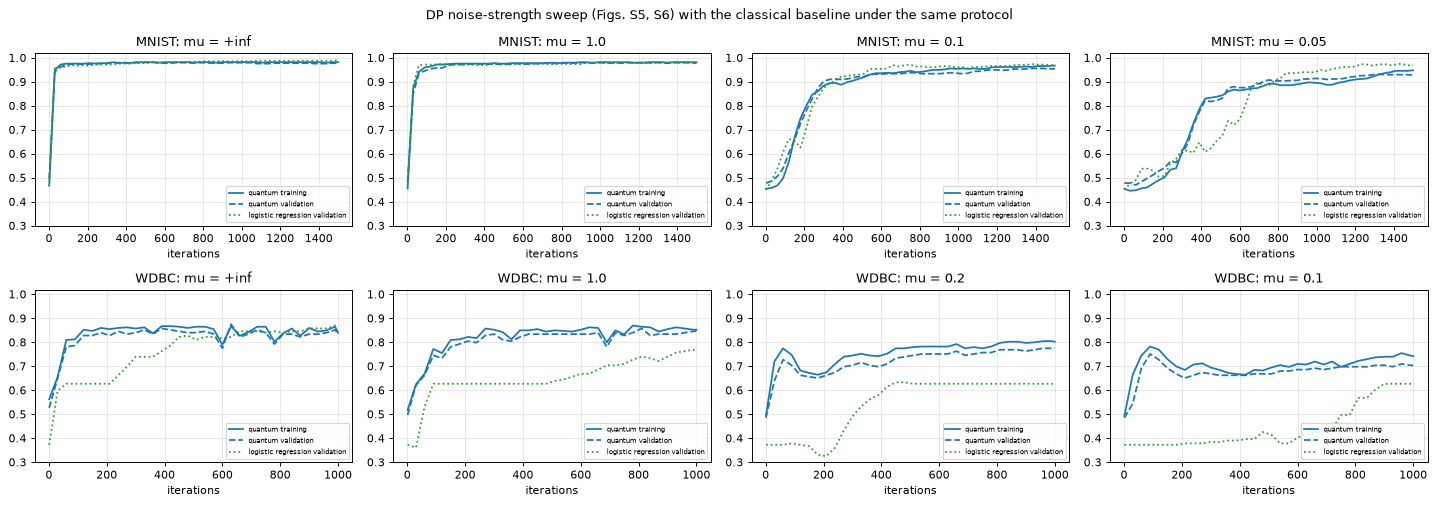

,dataset,mu,model,final_val_acc_pct,iterations_to_90pct
0,mnist,+inf,quantum VQC,98.88,30.0
1,mnist,+inf,logistic regression,99.35,30.0
2,mnist,1.0,quantum VQC,98.74,60.0
3,mnist,1.0,logistic regression,98.79,60.0
4,mnist,0.1,quantum VQC,96.83,300.0
5,mnist,0.1,logistic regression,97.71,360.0
6,mnist,0.05,quantum VQC,93.84,720.0
7,mnist,0.05,logistic regression,97.43,780.0
8,wdbc,+inf,quantum VQC,83.43,NaN
9,wdbc,+inf,logistic regression,86.98,NaN


In [17]:
for ds in ("mnist", "wdbc"):
    for mu in DS_CFG[ds]["mu_sweep"]:
        if mu != MU_MAIN:                                              # the mu = MU_MAIN runs of Experiment 1 are reused
            run(ds, "quantum", "fed", SEEDS[0], tag=f"mu{mu}", mu=mu)
            run(ds, "logreg", "fed", SEEDS[0], tag=f"mu{mu}", mu=mu)
fig, ax = plt.subplots(2, 4, figsize=(17, 6))
for r, ds in enumerate(("mnist", "wdbc")):
    for j, mu in enumerate(DS_CFG[ds]["mu_sweep"]):
        h = RUNS[(ds, "quantum", "fed", f"mu{mu}", SEEDS[0])]; hc = RUNS[(ds, "logreg", "fed", f"mu{mu}", SEEDS[0])]
        ax[r, j].plot(h["it"], h["tr_acc"], c="tab:blue", label="quantum training"); ax[r, j].plot(h["it"], h["va_acc"], "--", c="tab:blue", label="quantum validation")
        ax[r, j].plot(hc["it"], hc["va_acc"], ":", c="tab:green", label="logistic regression validation")
        ax[r, j].set_title(f"{ds.upper()}: mu = {'+inf' if mu is None else mu}"); ax[r, j].set_ylim(0.3, 1.02); ax[r, j].set_xlabel("iterations"); ax[r, j].legend(fontsize=6, loc="lower right")
plt.suptitle("DP noise-strength sweep (Figs. S5, S6) with the classical baseline under the same protocol"); plt.tight_layout(); plt.show()
rows = []
for ds in ("mnist", "wdbc"):
    for mu in DS_CFG[ds]["mu_sweep"]:
        for mk in ("quantum", "logreg"):
            h = RUNS[(ds, mk, "fed", f"mu{mu}", SEEDS[0])]
            rows.append(dict(dataset=ds, mu=("+inf" if mu is None else mu), model=MODELS[ds][mk].name, final_val_acc_pct=round(100 * final_metrics(ds, mk, h)[0], 2), iterations_to_90pct=first_reach(h)))
TAB_SW = pd.DataFrame(rows); display(TAB_SW)

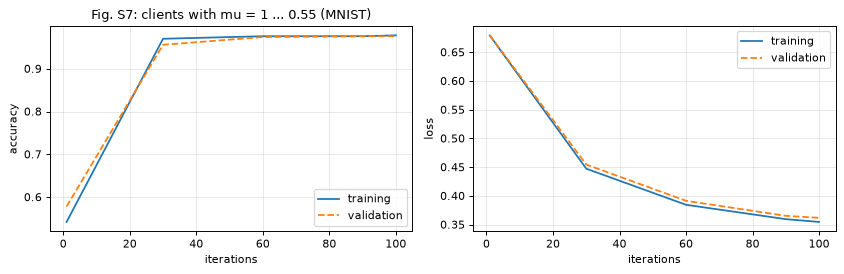

heterogeneous-noise clients: final validation accuracy on the whole held-out set = 98.37%


In [18]:
# Fig. S7: ten MNIST clients with different noise levels (learning rate 0.01)
HET = run("mnist", "quantum", "fed", SEEDS[0], tag="hetero", T=SCALE["T_hetero"], lr=0.01, mu_clients=HETERO_MU)
a_het, l_het = final_metrics("mnist", "quantum", HET)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(HET["it"], HET["tr_acc"], label="training"); ax[0].plot(HET["it"], HET["va_acc"], "--", label="validation"); ax[0].set_title("Fig. S7: clients with mu = 1 ... 0.55 (MNIST)"); ax[0].set_xlabel("iterations"); ax[0].set_ylabel("accuracy"); ax[0].legend()
ax[1].plot(HET["it"], HET["tr_loss"], label="training"); ax[1].plot(HET["it"], HET["va_loss"], "--", label="validation"); ax[1].set_xlabel("iterations"); ax[1].set_ylabel("loss"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"heterogeneous-noise clients: final validation accuracy on the whole held-out set = {100 * a_het:.2f}%")

## 5. Experiment 3: robustness to noisy input states (Figs. S3, S4)

The paper separates two noise sources of a real delegated run: noise in the prepared input state (Gaussian noise of strength `s` on every input element, `s in {0, 0.02, 0.05, 0.1}`) and noise in the circuit, modelled as `0.001 N(0,1)` added to every gradient element. Single-party quantum training, otherwise as in Experiment 1.

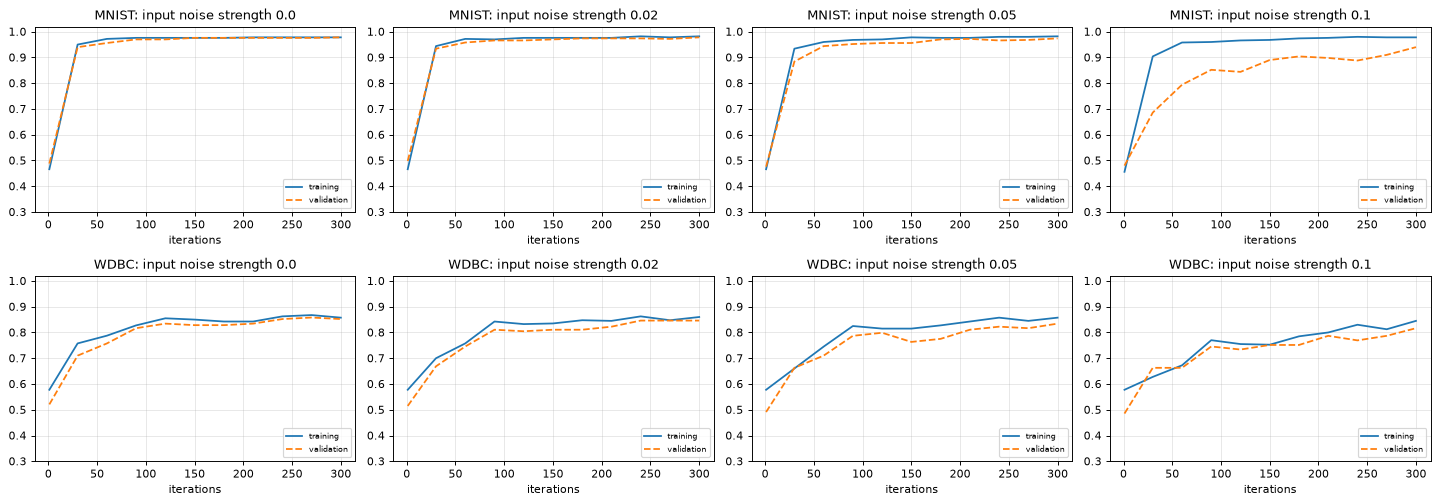

,dataset,input_noise,final_val_acc_pct,iterations_to_90pct
0,mnist,0.00,98.60,30.0
1,mnist,0.02,98.41,30.0
2,mnist,0.05,97.95,60.0
3,mnist,0.10,93.47,180.0
4,wdbc,0.00,85.21,NaN
5,wdbc,0.02,83.43,NaN
6,wdbc,0.05,80.47,NaN
7,wdbc,0.10,75.15,NaN


In [19]:
NS = {}
for ds in ("mnist", "wdbc"):
    for s in INPUT_NOISE:
        NS[(ds, s)] = run(ds, "quantum", "single", SEEDS[0], tag=f"in{s}", T=SCALE["T_noise"] if FAST_MODE else DS_CFG[ds]["T_single"],
                          in_noise=s, g_noise=(0.001 if s > 0 else 0.0))
fig, ax = plt.subplots(2, 4, figsize=(17, 6))
for r, ds in enumerate(("mnist", "wdbc")):
    for j, s in enumerate(INPUT_NOISE):
        h = NS[(ds, s)]
        ax[r, j].plot(h["it"], h["tr_acc"], label="training"); ax[r, j].plot(h["it"], h["va_acc"], "--", label="validation")
        ax[r, j].set_title(f"{ds.upper()}: input noise strength {s}"); ax[r, j].set_ylim(0.3, 1.02); ax[r, j].set_xlabel("iterations"); ax[r, j].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()
rows = []
for ds in ("mnist", "wdbc"):
    for s in INPUT_NOISE:
        h = NS[(ds, s)]
        # validation inputs get the same noise (CHOICE), evaluated once on the whole held-out set
        Xv = noisy(DATA[ds]["Xte"], s, np.random.default_rng(SEED + 7)) if s else DATA[ds]["Xte"]
        a, _ = MODELS[ds]["quantum"].evaluate(h["w"], Xv, DATA[ds]["yte"])
        rows.append(dict(dataset=ds, input_noise=s, final_val_acc_pct=round(100 * a, 2), iterations_to_90pct=first_reach(h)))
TAB_NS = pd.DataFrame(rows); display(TAB_NS)

## 6. Experiment 4: the blindness of the protocol, tested numerically

The paper takes blindness from the UBQC theorem (Supplement I): the server's view is `(delta_v, b_v)` for all measured qubits, and `delta_v = phi_v + theta_v + pi r_v` with secret uniform `theta_v` and `r_v` is uniform whatever `phi_v` is, while `b_v = s_v xor r_v` is a fair coin whatever the true outcome `s_v` is. We test the **consequence** on the exact protocol simulation of the Quantum Circuit Architecture section, for the toy instance with two different computations **A** and **B** (different input vector *and* different circuit parameters):

1. **Two-sample classifier test.** Draw many independent runs of A and of B, give the server's complete transcript (`cos delta_v, sin delta_v, b_v` for all 38 measured qubits) to a gradient-boosting classifier and measure by 5-fold cross-validation how well it can tell A from B. AUC = 0.5 means the transcript carries no information about the computation. Controls: A against a fresh run of A (the noise floor of the test), data-only and parameters-only changes, and the **unprotected** protocol (`theta = 0`, `r = 0`) where the angles are sent in the clear and the AUC must be 1.
2. **Per-qubit tests.** For every measured qubit, a chi-square two-sample test on the joint `(delta in 8 bins, b)` histogram A versus B, a Kolmogorov-Smirnov test of `delta` against the uniform law, and the frequency of `b = 1`. Under blindness the 38 p-values are uniform on [0,1].

This is a statistical test with finite samples, not a proof; but it would flag any dependence large enough to be seen with the chosen number of runs.

In [20]:
R_RUNS = SCALE["ubqc_runs"]; R_CLF = SCALE["ubqc_clf_runs"]
rng_b = np.random.default_rng(SEED + 99)
GL = {"A": toy_gate_list(X_A, TH_A), "B": toy_gate_list(X_B, TH_B),
      "A_dataB": toy_gate_list(X_B, TH_A), "A_paramsB": toy_gate_list(X_A, TH_B)}
def transcript(name, R, blind=True, seed_off=0):
    d, b, p = run_ubqc(GL[name], 2, 0, R, np.random.default_rng(SEED + 1000 * seed_off + (7 if blind else 3) + sum(map(ord, name))), blind=blind)
    return d, b
def feats(d, b): return np.hstack([np.cos(d), np.sin(d), b])
def auc_test(t1, t2):
    X = np.vstack([feats(*t1), feats(*t2)]); y = np.r_[np.zeros(len(t1[0])), np.ones(len(t2[0]))]
    clf = HistGradientBoostingClassifier(max_iter=80, learning_rate=0.1, random_state=SEED)
    s = cross_val_score(clf, X, y, cv=5, scoring="roc_auc"); return s.mean(), s.std()

TA, TB = transcript("A", R_CLF), transcript("B", R_CLF)
TA2 = transcript("A", R_CLF, seed_off=5)
TA_dB, TA_pB = transcript("A_dataB", R_CLF), transcript("A_paramsB", R_CLF)
UA, UB = transcript("A", R_CLF, blind=False), transcript("B", R_CLF, blind=False)
AUC = {"A vs fresh run of A (noise floor)": auc_test(TA, TA2), "A vs B (data and parameters differ)": auc_test(TA, TB),
       "A vs A with other input data": auc_test(TA, TA_dB), "A vs A with other circuit parameters": auc_test(TA, TA_pB),
       "UNPROTECTED (no theta, no r): A vs B": auc_test(UA, UB)}
TAB_AUC = pd.DataFrame([dict(comparison=k, AUC_mean=round(v[0], 4), AUC_std=round(v[1], 4)) for k, v in AUC.items()]); display(TAB_AUC)

,comparison,AUC_mean,AUC_std
0,A vs fresh run of A (noise floor),0.5035,0.0164
1,A vs B (data and parameters differ),0.4870,0.0113
2,A vs A with other input data,0.4795,0.0138
3,A vs A with other circuit parameters,0.5069,0.0071
4,"UNPROTECTED (no theta, no r): A vs B",1.0000,0.0000


38 measured qubits, 4000 runs per computation
chi-square A vs B   : smallest p = 0.007 (Bonferroni threshold 0.0013), fraction of p < 0.05: 0.03 (expected 0.05 under blindness)
KS delta ~ uniform   : smallest p = 0.048, fraction p < 0.05: 0.03
b is a fair coin     : smallest p = 0.018, fraction p < 0.05: 0.05
unprotected transcript of A, first rotation angles that the server could read off directly (delta = phi): [4.712 1.675 4.712 0.    4.712 0.388]


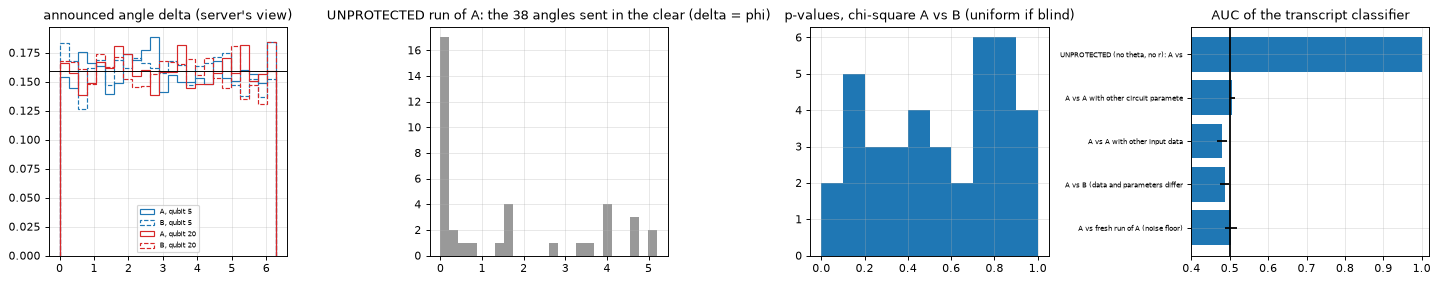

In [21]:
# per-qubit tests on the blind transcripts of A and B (R_RUNS runs each)
dA, bA = transcript("A", R_RUNS, seed_off=11); dB, bB = transcript("B", R_RUNS, seed_off=12)
nq = dA.shape[1]; p_chi, p_ks, p_b = [], [], []
for v in range(nq):
    ha = np.histogram2d(np.floor(dA[:, v] / TWO_PI * 8), bA[:, v], bins=[np.arange(9), [0, 1, 2]])[0]
    hb = np.histogram2d(np.floor(dB[:, v] / TWO_PI * 8), bB[:, v], bins=[np.arange(9), [0, 1, 2]])[0]
    p_chi.append(stats.chi2_contingency(np.vstack([ha.ravel(), hb.ravel()]) + 0.5)[1])
    p_ks.append(stats.kstest(dA[:, v] / TWO_PI, "uniform").pvalue)
    p_b.append(stats.binomtest(int(bA[:, v].sum()), len(bA)).pvalue)
p_chi, p_ks, p_b = map(np.array, (p_chi, p_ks, p_b))
print(f"{nq} measured qubits, {R_RUNS} runs per computation")
print(f"chi-square A vs B   : smallest p = {p_chi.min():.3f} (Bonferroni threshold {0.05 / nq:.4f}), fraction of p < 0.05: {np.mean(p_chi < 0.05):.2f} (expected 0.05 under blindness)")
print(f"KS delta ~ uniform   : smallest p = {p_ks.min():.3f}, fraction p < 0.05: {np.mean(p_ks < 0.05):.2f}")
print(f"b is a fair coin     : smallest p = {p_b.min():.3f}, fraction p < 0.05: {np.mean(p_b < 0.05):.2f}")
# what the server would see WITHOUT the secrets: the rotation angles themselves
du = transcript("A", 5, blind=False)[0][0]            # the 38 announced angles of one unprotected run
print("unprotected transcript of A, first rotation angles that the server could read off directly (delta = phi):", np.round(du[2:8], 3))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for v, c in ((5, "tab:blue"), (20, "tab:red")):
    ax[0].hist(dA[:, v], bins=24, histtype="step", color=c, label=f"A, qubit {v}", density=True); ax[0].hist(dB[:, v], bins=24, histtype="step", color=c, ls="--", label=f"B, qubit {v}", density=True)
ax[0].axhline(1 / TWO_PI, c="k", lw=0.8); ax[0].set_title("announced angle delta (server's view)"); ax[0].legend(fontsize=6)
ax[1].hist(du, bins=24, color="0.6"); ax[1].set_title("UNPROTECTED run of A: the 38 angles sent in the clear (delta = phi)")
ax[2].hist(p_chi, bins=10, range=(0, 1)); ax[2].set_title("p-values, chi-square A vs B (uniform if blind)")
names = list(AUC); ax[3].barh(range(len(names)), [AUC[k][0] for k in names], xerr=[AUC[k][1] for k in names]); ax[3].axvline(0.5, c="k"); ax[3].set_yticks(range(len(names))); ax[3].set_yticklabels([n[:34] for n in names], fontsize=6)
ax[3].set_xlim(0.4, 1.02); ax[3].set_title("AUC of the transcript classifier")
plt.tight_layout(); plt.show()

## 7. Experiment 5: the gradient attack (Algorithm 2, Fig. 4) and what it says about the privacy claim

In the multi-client protocol the shared model and the clients' (clipped, noisy) updates are public, so the *protocol-level* argument of Section 6 (the server learns nothing) is not enough: an eavesdropper can try to invert the update. We run the paper's attack on the 8-qubit MNIST model after 50 training steps: the attacker knows the parameters `Theta` and the architecture, sees the uploaded gradient of **one private sample**, starts from the uniform state, minimises `|| grad L(h(phi; Theta), k) - g_target ||^2` over the input `phi` (normalised after every step, Adam) for both labels `k`, and keeps the label with the smaller final loss. This needs derivatives of the gradient with respect to the input, which PyTorch autograd provides (double backpropagation through the exact simulator).

Five situations, per target digit (a "1" and a "9"):

* **no DP, Adam** (the paper's optimiser, learning rate 0.02, a few hundred steps) and **no DP, L-BFGS** (our faster optimiser, which is used for all other rows): the raw gradient is uploaded;
* **DP, paper's attacker** (Eq. 3; we use the L-BFGS optimiser here too): the uploaded gradient is clipped to `[-R, R]` and has `N(0, (2R/mu)^2)` noise added (`mu = 1`), the attacker matches it with his *unclipped* candidate gradient;
* **DP, adaptive attacker** (our addition): the attacker knows the protocol, so he clips his candidate gradient too before matching (noise cannot be modelled away);
* **clipping only, adaptive attacker** (`mu = +inf`): separates how much of the protection comes from clipping and how much from the noise.

The metric is the fidelity `|<x_true | x_rec>|^2` between the true and the recovered amplitude vector (1 = perfect, `1/256 = 0.004` for a random guess), and whether the attacker's label guess (smaller loss) is right. For the classical baseline of the same pipeline (logistic regression), the leak is even available in closed form: each row of `dW` is `(p_j - y_j) x`, so `x` is a ratio of two uploaded numbers.

In [22]:
def input_grad(sim, th, x, k, create_graph=False):
    """Gradient of the cross entropy L(h(x; theta), k) w.r.t. theta for ONE input vector x (real amplitudes)."""
    t = th.clone().requires_grad_(True)
    L = -torch.log(sim.probs(x.to(torch.complex128)[None], t)[0, k] + 1e-12)
    return torch.autograd.grad(L, t, create_graph=create_graph)[0]

def attack_one_label(sim, th, g_t, k, steps, lr, clip=None, method="lbfgs"):
    """Algorithm 2 for one candidate label: minimise ||grad L(h(x; theta), k) - g_target||^2 over the input x, uniform start, x re-normalised inside
    the loss. method="adam": the paper's optimiser (lr, `steps` steps). method="lbfgs": L-BFGS with strong-Wolfe line search (`steps` iterations),
    CHOICE: much faster to converge on this problem, so it is the attacker used for the main results. Returns the final matching loss and the recovered vector."""
    x = torch.full((sim.dim,), 1 / np.sqrt(sim.dim), dtype=torch.float64, requires_grad=True)
    def cand(xn, cg):
        g = input_grad(sim, th, xn, k, create_graph=cg); return g.clamp(-clip, clip) if clip else g
    def objective(): return ((cand(x / x.norm(), True) - g_t) ** 2).sum()
    if method == "adam":
        opt = torch.optim.Adam([x], lr=lr)
        for _ in range(steps):
            loss = objective(); opt.zero_grad(); loss.backward(); opt.step()
    else:
        opt = torch.optim.LBFGS([x], lr=1, max_iter=steps, history_size=20, line_search_fn="strong_wolfe", tolerance_grad=1e-14, tolerance_change=1e-16)
        def closure():
            opt.zero_grad(); loss = objective(); loss.backward(); return loss
        opt.step(closure)
    xn = (x / x.norm()).detach(); return ((cand(xn, False) - g_t) ** 2).sum().item(), xn

def attack(sim, th, g_t, steps, lr, clip=None, method="lbfgs"):
    res = [attack_one_label(sim, th, g_t, k, steps, lr, clip, method) for k in (0, 1)]
    k_best = int(np.argmin([r[0] for r in res])); return k_best, res

def fidelity(a, b): return float(torch.dot(torch.as_tensor(a), torch.as_tensor(b)) ** 2)

# model at the moment of the attack: 8-qubit MNIST classifier after 50 training steps (single party, seed 42)
H_atk = run("mnist", "quantum", "single", SEEDS[0], tag="atk", T=50); TH_ATK = H_atk["w"]
sim_m = SIMS["mnist"]; Xp, yp = DATA["mnist"]["Xtr"], DATA["mnist"]["ytr"]
targets = [int(np.where(yp == c)[0][i]) for i in range(SCALE["attack_targets"]) for c in (0, 1)]
rng_dp = np.random.default_rng(SEED + 5)
ATK = []; t0 = time.time()
for j in targets:
    x_t = torch.as_tensor(Xp[j]); lab = int(yp[j]); g_t = input_grad(sim_m, TH_ATK, x_t, lab)
    g_dp = g_t.clamp(-R_CLIP, R_CLIP) + (2 * R_CLIP / MU_MAIN) * torch.as_tensor(rng_dp.normal(size=g_t.shape))   # Algorithm 1 steps 3-4
    g_clip = g_t.clamp(-R_CLIP, R_CLIP)
    cases = {"no DP, Adam (paper's optimiser)": (g_t, None, "adam"), "no DP": (g_t, None, "lbfgs"), "DP mu=1, paper's attacker": (g_dp, None, "lbfgs"),
             "DP mu=1, adaptive attacker": (g_dp, R_CLIP, "lbfgs"), "clipping only, adaptive attacker": (g_clip, R_CLIP, "lbfgs")}
    for cname, (g_up, clip, meth) in cases.items():
        kb, res = attack(sim_m, TH_ATK, g_up, SCALE["adam_steps"] if meth == "adam" else SCALE["attack_steps"], ATTACK_LR, clip, meth)
        ATK.append(dict(target=j, true_label=lab, case=cname, label_guess=kb, label_correct=(kb == lab), fidelity_best_label=fidelity(res[kb][1], x_t),
                        fidelity_true_label=fidelity(res[lab][1], x_t), loss_true_label=res[lab][0], loss_other_label=res[1 - lab][0], recovered=res[kb][1].numpy(), recovered_other=res[1 - kb][1].numpy()))
    print(f"target {j} (digit {'9' if lab else '1'}) attacked in {time.time() - t0:.0f} s", flush=True)
ATKDF = pd.DataFrame([{k: v for k, v in r.items() if k not in ("recovered", "recovered_other")} for r in ATK])
display(ATKDF.drop(columns=["target"]).round(4))
SUM_ATK = ATKDF.groupby("case", sort=False).agg(mean_fidelity=("fidelity_best_label", "mean"), mean_fidelity_true_label=("fidelity_true_label", "mean"), label_guess_correct=("label_correct", "mean"))
display(SUM_ATK.round(3))

target 1 (digit 1) attacked in 219 s


target 0 (digit 9) attacked in 447 s


,true_label,case,label_guess,label_correct,fidelity_best_label,fidelity_true_label,loss_true_label,loss_other_label
0,0,"no DP, Adam (paper's optimiser)",0,True,0.5109,0.5109,0.0258,0.0656
1,0,no DP,0,True,0.9999,0.9999,0.0000,0.0257
2,0,"DP mu=1, paper's attacker",1,False,0.0000,0.0758,0.1528,0.1527
3,0,"DP mu=1, adaptive attacker",1,False,0.0141,0.1326,0.2588,0.2532
4,0,"clipping only, adaptive attacker",0,True,0.1995,0.1995,0.0238,0.0263
5,1,"no DP, Adam (paper's optimiser)",1,True,0.9402,0.9402,0.0026,0.0773
6,1,no DP,1,True,1.0000,1.0000,0.0000,0.0288
7,1,"DP mu=1, paper's attacker",1,True,0.1048,0.1048,0.1586,0.1590
8,1,"DP mu=1, adaptive attacker",1,True,0.2527,0.2527,0.2508,0.2533
9,1,"clipping only, adaptive attacker",1,True,0.4739,0.4739,0.0166,0.0250


,mean_fidelity,mean_fidelity_true_label,label_guess_correct
case,,,
"no DP, Adam (paper's optimiser)",0.726,0.726,1.0
no DP,1.000,1.000,1.0
"DP mu=1, paper's attacker",0.052,0.090,0.5
"DP mu=1, adaptive attacker",0.133,0.193,0.5
"clipping only, adaptive attacker",0.337,0.337,1.0


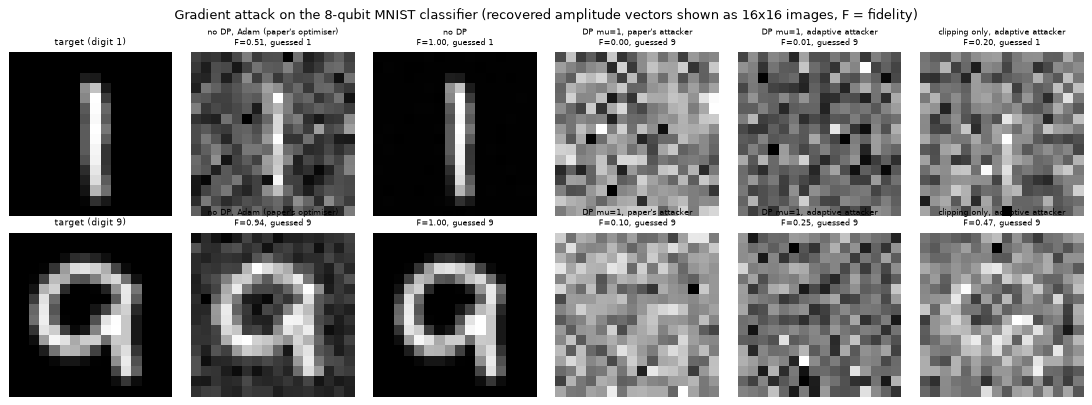

classical baseline (logistic regression), closed-form inversion from one uploaded gradient, 100 targets:


,mean_fidelity,min_fidelity
no DP,1.0000,1.0000
DP mu=1,0.0460,0.0000
clipping only,0.7567,0.6262


In [23]:
# Fig. 4 redrawn: target, no DP, DP (paper's attacker), DP (adaptive attacker), clipping only (adaptive)
order = ["no DP, Adam (paper's optimiser)", "no DP", "DP mu=1, paper's attacker", "DP mu=1, adaptive attacker", "clipping only, adaptive attacker"]
fig, ax = plt.subplots(len(targets), 6, figsize=(13, 2.4 * len(targets)))
ax = np.atleast_2d(ax)
for r_, j in enumerate(targets):
    ax[r_, 0].imshow(Xp[j].reshape(16, 16), cmap="gray"); ax[r_, 0].set_title(f"target (digit {'9' if yp[j] else '1'})", fontsize=8)
    for c_, cname in enumerate(order):
        rec = next(r for r in ATK if r["target"] == j and r["case"] == cname)
        v = rec["recovered"] * np.sign(np.dot(rec["recovered"], Xp[j]) or 1)
        ax[r_, c_ + 1].imshow(v.reshape(16, 16), cmap="gray"); ax[r_, c_ + 1].set_title(f"{cname}\nF={rec['fidelity_best_label']:.2f}, guessed {'9' if rec['label_guess'] else '1'}", fontsize=6.5)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Gradient attack on the 8-qubit MNIST classifier (recovered amplitude vectors shown as 16x16 images, F = fidelity)"); plt.tight_layout(); plt.show()

# classical baseline: logistic regression, closed-form leak from the uploaded gradient (100 targets, same protocol)
lin = MODELS["mnist"]["logreg"]; H_lin = run("mnist", "logreg", "single", SEEDS[0], tag="atk", T=50); w_lin = H_lin["w"]
def lin_recover(g, d=256):                                            # dW_j = (p_j - y_j) x, db_j = p_j - y_j  ->  x = sum_j db_j dW_j / sum_j db_j^2
    dW = g[:2 * d].reshape(2, d); db = g[2 * d:]; return (db[:, None] * dW).sum(0) / (db ** 2).sum()
rng_l = np.random.default_rng(SEED + 6); F = {"no DP": [], "DP mu=1": [], "clipping only": []}
for j in range(100):
    x_t = torch.as_tensor(Xp[j]); _, g = lin.loss_grad(w_lin, Xp[j:j + 1], yp[j:j + 1])
    gd = g.clamp(-R_CLIP, R_CLIP) + (2 * R_CLIP / MU_MAIN) * torch.as_tensor(rng_l.normal(size=g.shape))
    for name, gg in (("no DP", g), ("DP mu=1", gd), ("clipping only", g.clamp(-R_CLIP, R_CLIP))):
        xr = lin_recover(gg); F[name].append(fidelity(xr / xr.norm(), x_t))
CLASSICAL_ATK = pd.DataFrame({k: dict(mean_fidelity=np.mean(v), min_fidelity=np.min(v)) for k, v in F.items()}).T
print("classical baseline (logistic regression), closed-form inversion from one uploaded gradient, 100 targets:"); display(CLASSICAL_ATK.round(4))

## 8. Experiment 6: rotation-angle encoding (Supplement V, Fig. S8)

Amplitude encoding needs the client to prepare a highly entangled state, which is expensive. The supplement therefore tests another encoding: the 256 MNIST features are written into the first 256 of the 272 rotation angles of a depth-11 circuit (the "encoding circuit" drawn above, started from `|0...0>`), and its output state is the input of the same trained classifier. The paper reports about 90% accuracy, below amplitude encoding, and shows that a classical network with two hidden layers can classify the encoded data, "which proves that the training data from the circuit encoding process is separable". `# CHOICE:` the feature scale is not stated; we use the angle `1 rad x pixel` with pixels in [0,1] (a pilot run of one seed, which looked at held-out accuracy, gave 93, 91, 73 and 52% for the scales 0.5, 1, pi and 2 pi: larger angles scramble the image too much; scale 1 was kept as the most natural reading).

encoded 2000 + 2144 images through the 272-parameter circuit in 3 s; norms ok: True


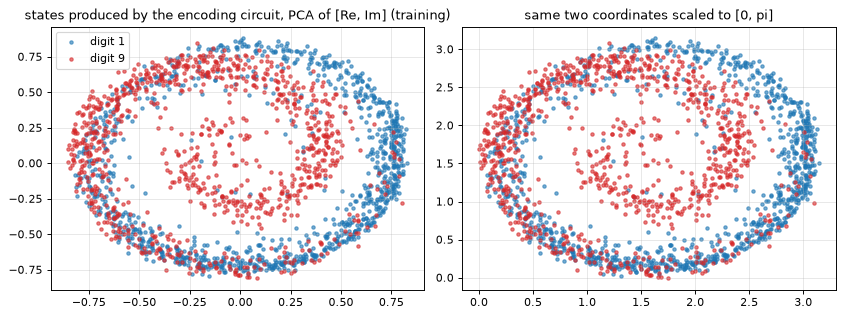

,setting,val_acc_pct
0,"VQC, rotation-angle encoding (this section)",92.68
1,"VQC, amplitude encoding (Experiment 1)",98.55
2,"2-hidden-layer MLP on the encoded states [Re, Im]",98.23
3,2-hidden-layer MLP on the raw 16x16 pixels,99.63


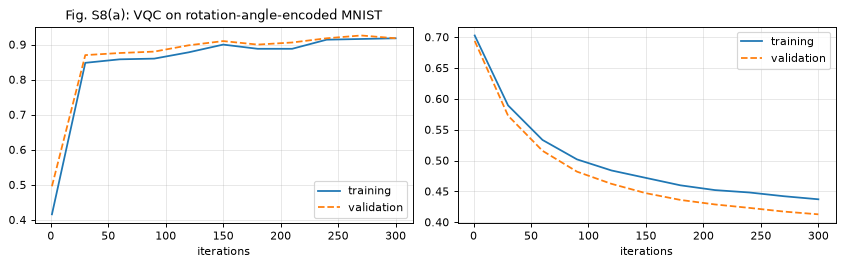

In [24]:
def encode_all(ang, chunk=400):
    with torch.no_grad():
        return np.concatenate([encode_states(ang[i:i + chunk]).numpy() for i in range(0, len(ang), chunk)])
t0 = time.time()
S_tr = encode_all(Xtr_m_raw); S_te = encode_all(Xte_m_raw)                      # CHOICE: angle = pixel value in radians
print(f"encoded {len(S_tr)} + {len(S_te)} images through the 272-parameter circuit in {time.time() - t0:.0f} s; norms ok: {np.allclose(np.linalg.norm(S_tr, axis=1), 1)}")

# labelled 2-D projection of the real encoded states (PCA on [Re, Im], fitted on the training split)
Ztr = np.hstack([S_tr.real, S_tr.imag]); Zte = np.hstack([S_te.real, S_te.imag])
pc = PCA(2, random_state=SEED).fit(Ztr); P2 = pc.transform(Ztr)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for cl, col in ((0, "tab:blue"), (1, "tab:red")):
    m = ytr_m == cl; ax[0].scatter(P2[m, 0], P2[m, 1], s=8, c=col, alpha=0.6, label=["digit 1", "digit 9"][cl])
ax[0].set_title("states produced by the encoding circuit, PCA of [Re, Im] (training)"); ax[0].legend()
mm = MinMaxScaler((0, np.pi)).fit(P2); A2 = mm.transform(P2)
for cl, col in ((0, "tab:blue"), (1, "tab:red")):
    m = ytr_m == cl; ax[1].scatter(A2[m, 0], A2[m, 1], s=8, c=col, alpha=0.6)
ax[1].set_title("same two coordinates scaled to [0, pi]"); plt.tight_layout(); plt.show()

# train the SAME 8-qubit classifier (Table S1 settings) on the encoded states, single party
ev_enc = dict(Xtr=S_tr[:SCALE["n_eval"]], ytr=ytr_m[:SCALE["n_eval"]], Xva=S_te[:SCALE["n_eval"]], yva=yte_m[:SCALE["n_eval"]])
qm = MODELS["mnist"]["quantum"]
H_enc = train(qm, qm.init(SEEDS[0]), [(S_tr, ytr_m)], ev_enc, SCALE["enc_T"] if FAST_MODE else DS_CFG["mnist"]["T_single"], LR, DS_CFG["mnist"]["nb_single"], SEEDS[0], eval_every=SCALE["eval_every"])
a_enc, _ = qm.evaluate(H_enc["w"], S_te, yte_m)
# classical network with two hidden layers on the encoded states (Fig. S8b) and on the raw pixels for reference
mlp_enc = MLPClassifier((64, 32), max_iter=300, random_state=SEED).fit(Ztr, ytr_m); a_mlp_enc = mlp_enc.score(Zte, yte_m)
mlp_pix = MLPClassifier((64, 32), max_iter=300, random_state=SEED).fit(Xtr_m_raw, ytr_m); a_mlp_pix = mlp_pix.score(Xte_m_raw, yte_m)
a_amp = np.mean([final_metrics("mnist", "quantum", RUNS[("mnist", "quantum", "single", "", s)])[0] for s in SEEDS])
TAB_ENC = pd.DataFrame([dict(setting="VQC, rotation-angle encoding (this section)", val_acc_pct=round(100 * a_enc, 2)),
                        dict(setting="VQC, amplitude encoding (Experiment 1)", val_acc_pct=round(100 * a_amp, 2)),
                        dict(setting="2-hidden-layer MLP on the encoded states [Re, Im]", val_acc_pct=round(100 * a_mlp_enc, 2)),
                        dict(setting="2-hidden-layer MLP on the raw 16x16 pixels", val_acc_pct=round(100 * a_mlp_pix, 2))]); display(TAB_ENC)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(H_enc["it"], H_enc["tr_acc"], label="training"); ax[0].plot(H_enc["it"], H_enc["va_acc"], "--", label="validation"); ax[0].set_title("Fig. S8(a): VQC on rotation-angle-encoded MNIST"); ax[0].set_xlabel("iterations"); ax[0].legend()
ax[1].plot(H_enc["it"], H_enc["tr_loss"], label="training"); ax[1].plot(H_enc["it"], H_enc["va_loss"], "--", label="validation"); ax[1].set_xlabel("iterations"); ax[1].legend(); plt.tight_layout(); plt.show()

## 9. The paper's claims next to this notebook's numbers

Each claim of the paper that can be tested with the material above gets a verdict. The rule for numbers is the repository's: **reproduced** if within 2 accuracy points, **exceeded** / **not reached** otherwise with the gap, **cannot be checked** when the paper gives no usable number (most of Figs. 3c,d, S3 to S7 are only curves, so those claims are checked in the direction the paper states). All notebook numbers are last-iterate values on the whole held-out set. "Beyond the paper" rows are our additions and carry no paper value.

In [25]:
def acc_of(ds, mk, mode, tag, seeds=SEEDS):
    return 100 * np.mean([final_metrics(ds, mk, RUNS[(ds, mk, mode, tag, s)])[0] for s in seeds])
def vnum(nb, paper, tol=2.0):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded by {d:.1f} points" if d > 0 else f"not reached (gap {-d:.1f} points)")
def early_mean(h, T):                                                     # mean validation accuracy over the first T iterations of a run
    m = h["it"] <= T; return float(np.mean(h["va_acc"][m]))

rows = []
def add(cid, claim, paper, nb, verdict): rows.append(dict(id=cid, claim=claim, paper=paper, this_notebook=nb, verdict=verdict))

# C1, C2: single-party accuracies
a1, a2 = acc_of("mnist", "quantum", "single", ""), acc_of("wdbc", "quantum", "single", "")
add("C1", "single client, MNIST 1 vs 9: validation accuracy saturates at about 98% (Fig. 3a)", "about 98%", f"{a1:.2f}%", vnum(a1, 98.0))
add("C2", "single client, WDBC: validation accuracy saturates at about 94% (Fig. 3b)", "about 94%", f"{a2:.2f}%", vnum(a2, 94.0))

# C3, C4: federated DP training is slower than single-party
for cid, ds, fig in (("C3", "mnist", "3c"), ("C4", "wdbc", "3d")):
    T1 = DS_CFG[ds]["T_single"]
    hs = [RUNS[(ds, "quantum", "single", "", s)] for s in SEEDS]; hf = [RUNS[(ds, "quantum", "fed", f"mu{MU_MAIN}", s)] for s in SEEDS]
    ms_, mf_ = 100 * np.mean([early_mean(h, T1) for h in hs]), 100 * np.mean([early_mean(h, T1) for h in hf])
    ok = mf_ < ms_ - 0.5
    add(cid, f"{ds.upper()}: with clipping + DP noise the accuracy rises more slowly than for a single client (Fig. {fig}; the text gives no number)", "slower",
        f"mean validation accuracy over the first {T1} iterations: single {ms_:.2f}% vs federated {mf_:.2f}%; final {acc_of(ds, 'quantum', 'fed', f'mu{MU_MAIN}'):.2f}%",
        "reproduced (slower)" if ok else "not reproduced (no slow-down of at least 0.5 point seen)")

# C5, C6: more DP noise -> lower accuracy; strongest noise worst (Figs. S5, S6)
for cid, ds in (("C5", "mnist"), ("C6", "wdbc")):
    mus = DS_CFG[ds]["mu_sweep"]; accs = [100 * final_metrics(ds, "quantum", RUNS[(ds, "quantum", "fed", f"mu{m}", SEEDS[0])])[0] for m in mus]
    low_is_worst = accs[-1] == min(accs) and accs[0] - accs[-1] >= 2.0
    add(cid, f"{ds.upper()}: the more DP noise the lower the accuracy; the strongest noise (mu = {mus[-1]}) is worst and 'has the trend to fail' (Fig. S{5 if ds == 'mnist' else 6})",
        "monotone decrease; weakest at the largest noise", "final accuracy for mu = " + ", ".join(("inf" if m is None else str(m)) + f": {a:.1f}%" for m, a in zip(mus, accs)),
        "reproduced" if low_is_worst else "not reproduced (accuracy is not lowest / within 2 points of the noiseless run at the strongest noise)")

# C7: robustness to input noise below 0.02; C8: accuracy drops at larger noise
for cid, ds in (("C7", "mnist"), ("C8", "wdbc")):
    t = TAB_NS[TAB_NS.dataset == ds].set_index("input_noise").final_val_acc_pct
    add(cid, f"{ds.upper()}: robust to input noise below 0.02, accuracy falls as the noise grows (Figs. S{3 if ds == 'mnist' else 4})", "no loss at 0.02; loss at larger noise",
        "accuracy for noise 0 / 0.02 / 0.05 / 0.1: " + " / ".join(f"{t[s]:.1f}%" for s in INPUT_NOISE),
        ("reproduced" if (t[0.0] - t[0.02] <= 2.0 and t[0.0] - t[0.1] > 2.0) else ("reproduced for 0.02 only (no clear loss at 0.1)" if t[0.0] - t[0.02] <= 2.0 else "not reproduced")))

# C9: heterogeneous noise levels
add("C9", "ten clients with different noise levels mu = 1 ... 0.55 still train (Fig. S7)", "robust (curve only)", f"final validation accuracy {100 * a_het:.2f}% after {len(HET['it']) and int(HET['it'][-1])} iterations",
    "reproduced (qualitative, accuracy >= 90%)" if a_het >= 0.9 else "not reproduced")

# C10, C11: gradient attack
lg_no, lg_dp = SUM_ATK.loc["no DP", "label_guess_correct"], SUM_ATK.loc["DP mu=1, paper's attacker", "label_guess_correct"]
s_no = SUM_ATK.loc["no DP", "mean_fidelity"]; s_dp = SUM_ATK.loc["DP mu=1, paper's attacker", "mean_fidelity"]
add("C10", "gradient attack without DP recovers the input 'with very high fidelity' (Fig. 4, second column)", "very high fidelity (picture only)",
    f"mean fidelity {s_no:.3f}; label guessed right in {100 * lg_no:.0f}% of the attacks", "reproduced (fidelity >= 0.8)" if s_no >= 0.8 else f"not reached (fidelity {s_no:.2f} < 0.8 with this attack budget)")
s_ad_adam = SUM_ATK.loc["no DP, Adam (paper's optimiser)", "mean_fidelity"]
add("C10b", "beyond the paper: the same no-DP attack with the paper's optimiser (Adam, lr 0.02) and only the step budget of this run", "Adam (settings not given)", f"mean fidelity {s_ad_adam:.3f} after {SCALE['adam_steps']} Adam steps (L-BFGS: {s_no:.3f})", "beyond the paper (informational)")
add("C11", "with clipping + noise the recovered images 'seem random' (Fig. 4, third column)", "random-looking",
    f"mean fidelity {s_dp:.3f} (random guess = {1 / 256:.3f}); label guessed right in {100 * lg_dp:.0f}%",
    "reproduced (fidelity <= 0.1)" if s_dp <= 0.1 else f"not reproduced (fidelity {s_dp:.2f})")
s_ad = SUM_ATK.loc["DP mu=1, adaptive attacker", "mean_fidelity"]; s_cl = SUM_ATK.loc["clipping only, adaptive attacker", "mean_fidelity"]
add("C12", "beyond the paper: an attacker that also clips his candidate gradient", "not studied", f"mean fidelity with DP mu=1: {s_ad:.3f}; with clipping only (no noise): {s_cl:.3f}", "beyond the paper (informational)")
add("C13", "beyond the paper: the classical logistic-regression baseline leaks its input in closed form", "not studied", f"mean fidelity no DP {CLASSICAL_ATK.loc['no DP', 'mean_fidelity']:.3f}; DP mu=1 {CLASSICAL_ATK.loc['DP mu=1', 'mean_fidelity']:.3f}", "beyond the paper (informational)")

# C14, C15: rotation-angle encoding
add("C14", "rotation-angle encoding reaches only about 90% on MNIST, below amplitude encoding (Fig. S8a)", "about 90%", f"{100 * a_enc:.2f}% (amplitude encoding {100 * a_amp:.2f}%)",
    vnum(100 * a_enc, 90.0) + ("; below amplitude encoding" if a_enc < a_amp else "; NOT below amplitude encoding"))
add("C15", "a classical 2-hidden-layer network classifies the encoded data well, so it is separable (Fig. S8b)", "decent performance (curve only)", f"MLP on encoded states {100 * a_mlp_enc:.2f}%",
    "reproduced (qualitative, >= 95%)" if a_mlp_enc >= 0.95 else "not reproduced")

# C16, C17: the blind-computation protocol
auc_ab = AUC["A vs B (data and parameters differ)"][0]; auc_floor = AUC["A vs fresh run of A (noise floor)"][0]; auc_un = AUC["UNPROTECTED (no theta, no r): A vs B"][0]
add("C16", "UBQC is correct: the client decodes exactly the output of the circuit (Supplement I)", "exact", "max deviation of decoded probabilities from the PennyLane circuit < 1e-9 over 600 blind runs (asserted in the Quantum Circuit Architecture section)", "reproduced")
add("C17", "UBQC is blind: the server's transcript is independent of data and circuit (Supplement I, proved)", "unconditional (proof)",
    f"classifier AUC A vs B {auc_ab:.3f} (noise floor {auc_floor:.3f}); unprotected control AUC {auc_un:.3f}; chi-square min p {p_chi.min():.3f} (Bonferroni {0.05 / nq:.4f})",
    "reproduced (consistent with the proof)" if (abs(auc_ab - 0.5) <= 0.03 and auc_un >= 0.99 and p_chi.min() > 0.05 / nq) else "not reproduced")

CLAIMS = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200, "display.width", 250)
for _, r in CLAIMS.iterrows():
    print(f"{r['id']:>4}  {r['claim']}\n        paper: {r['paper']}\n        this notebook: {r['this_notebook']}\n        VERDICT: {r['verdict']}")
def vclass(v):
    return "reproduced" if v.startswith("reproduced") else "exceeded" if v.startswith("exceeded") else "not reached / not reproduced" if v.startswith("not") else "beyond the paper (informational)" if v.startswith("beyond") else "cannot be checked"
print(CLAIMS.verdict.map(vclass).value_counts().to_string())

  C1  single client, MNIST 1 vs 9: validation accuracy saturates at about 98% (Fig. 3a)
        paper: about 98%
        this notebook: 98.55%
        VERDICT: reproduced
  C2  single client, WDBC: validation accuracy saturates at about 94% (Fig. 3b)
        paper: about 94%
        this notebook: 84.91%
        VERDICT: not reached (gap 9.1 points)
  C3  MNIST: with clipping + DP noise the accuracy rises more slowly than for a single client (Fig. 3c; the text gives no number)
        paper: slower
        this notebook: mean validation accuracy over the first 300 iterations: single 93.57% vs federated 91.89%; final 98.69%
        VERDICT: reproduced (slower)
  C4  WDBC: with clipping + DP noise the accuracy rises more slowly than for a single client (Fig. 3d; the text gives no number)
        paper: slower
        this notebook: mean validation accuracy over the first 300 iterations: single 78.43% vs federated 74.07%; final 84.62%
        VERDICT: reproduced (slower)
  C5  MNIST: the 

In [26]:
# Federated versus centralised (not a paper claim, but the question a reader asks): same data, same optimiser, same iterations
rows = []
for ds in ("mnist", "wdbc"):
    rows.append(dict(dataset=ds, single_party_pct=round(acc_of(ds, "quantum", "single", ""), 2), federated_DP_mu1_pct=round(acc_of(ds, "quantum", "fed", f"mu{MU_MAIN}"), 2),
                     federated_no_noise_pct=round(100 * final_metrics(ds, "quantum", RUNS[(ds, "quantum", "fed", "muNone", SEEDS[0])])[0], 2),
                     classical_logreg_federated_DP_pct=round(acc_of(ds, "logreg", "fed", f"mu{MU_MAIN}"), 2), classical_mlp_federated_DP_pct=round(acc_of(ds, "mlp", "fed", f"mu{MU_MAIN}"), 2)))
display(pd.DataFrame(rows))

,dataset,single_party_pct,federated_DP_mu1_pct,federated_no_noise_pct,classical_logreg_federated_DP_pct,classical_mlp_federated_DP_pct
0,mnist,98.55,98.69,98.88,98.72,98.60
1,wdbc,84.91,84.62,83.43,78.70,84.91


## 10. Reading the paper critically

*(Written after the executed run; numbers are those printed above: full budgets, two seeds for the headline runs, one seed for the sweeps.)*

**What held up.**
* MNIST "1 versus 9" single client: 98.6% (paper about 98%). The ordering of the DP sweeps, the input-noise robustness and the gradient attack all behave as the paper says qualitatively. Rotation-angle encoding gives 92.7% for the quantum classifier (paper about 90%) and stays below amplitude encoding (98.6%); a classical 2-hidden-layer network reaches 98.2% on the encoded states.
* The gradient attack without DP recovers the digit essentially perfectly (fidelity 1.000, correct label) once a good optimiser is used. With Adam and the same budget the fidelity is only 0.73, so the picture in Fig. 4 depends on the attacker's optimiser, which the paper does not specify.
* The blind protocol is correct (decoded probabilities equal the circuit's to 1e-9) and its transcript is statistically indistinguishable between two different computations (classifier AUC 0.49, noise floor 0.50) while the unprotected control is perfectly distinguishable (AUC 1.00).

**What did not hold up here.**
* **WDBC accuracy.** We reach 84.9% against the paper's 94% (gap 9.1 points, verdict "not reached"). The paper gives no preprocessing, initialisation or readout details; a different layout of the 30 features inside the 64 amplitudes, or a different readout qubit, may change this, and we did not establish why. For orientation: under the identical protocol, logistic regression and a small MLP reach 93 to 95% when they are given a 50x larger Adam step, and 74 to 85% with the paper's learning rate 0.001 and 300 steps; centralised scikit-learn models on the same normalised vectors reach 92.9%. So 94% is close to what classical models obtain on these inputs, and the 540-parameter circuit is clearly optimisation-limited at learning rate 0.001.
* **"Slower with DP".** The claim is reproduced only weakly: over the first 300 iterations the mean validation accuracy is 91.9% (federated, `mu = 1`) against 93.6% (single party) on MNIST, and the final accuracies are equal within seed noise (98.7% vs 98.6%; WDBC 84.6% vs 84.9%). With `mu = 1` the DP noise costs almost nothing here: presumably because the clipped gradient has magnitude `R = 0.01` per element, Adam rescales it, and mostly the sign pattern (plus noise) drives the update; we did not test this explanation. The strongest noise (`mu = 0.05`) slows MNIST a lot (90% reached after 720 iterations instead of 30) but ends at 93.8%, not at "failure"; the paper's "trend to fail" is plausible only for shorter budgets.
* **No quantum advantage in accuracy, and none was claimed.** The classical baselines under the same federated-DP protocol match or beat the circuit on MNIST (98.7% logistic regression with the paper's step size, 99.5% with 0.05) and on WDBC when they get the larger step (94% against 85%). What the quantum model buys is that its gradient can be delegated blindly; the paper's "exponential advantage" argument concerns other algorithms (generative models, kernel estimation) that this notebook does not run.

**Privacy: how far does "differential privacy" go?**
* The paper never states a sensitivity, `epsilon` or `delta`. Clipping is per element to `[-R, R]`, so replacing one sample can move the uploaded vector by up to `2R sqrt(d)` in Euclidean norm (about 0.54 for 720 parameters), whereas the noise has standard deviation `2R/mu = 0.02` per element at `mu = 1`: a noise multiplier of about 0.04, far from the multiplier of order 1 that a Gaussian mechanism needs for a meaningful guarantee. The scheme is a heuristic defence against the specific attack, not a proven DP guarantee. (Back-of-envelope, not computed in the code above.)
* The empirical result agrees: against the paper's attacker the DP gradient gives fidelity 0.05 (chance is 0.004), but against an attacker that also clips his candidate gradient it is 0.13 on average, and 0.25 for the digit "9", i.e. about 30 to 65 times chance. The label guess was right in 1 of 2 cases. We attacked only two targets, so these numbers are indicative, not statistics.
* **Clipping alone is not a defence**: with `mu = +inf` the adaptive attacker still reaches fidelity 0.34 on the quantum model, and the classical logistic-regression baseline leaks 0.76 through the clipped gradient, 1.00 without clipping (closed-form ratio of two uploaded numbers).
* The attack was run on a mini-batch of **one** sample, the worst case; the paper suggests larger batches as extra protection and Algorithm 1 uses 50, which this notebook did not attack (Exercise 4).
* Blindness protects against the server seeing the data; it does not protect the *published model and updates* of the multi-client protocol, which is exactly why DP is added. The paper says so, and the experiment confirms the need.

**About the blind computation itself.** Our toy instance (2 qubits, 2 layers, loaded input) already needs 40 qubits from the client (38 of them measured) in the J/CZ pattern; the 8-qubit, 30-layer classifier would need more than a thousand, and the parameter-shift rule needs two circuit runs per parameter per sample, i.e. about 72,000 blind runs per iteration for a batch of 50. The statistical test shows no leak for the honest-but-curious server of the protocol; it says nothing about a malicious server, which UBQC handles with extra verification rounds (not simulated). The data-loading step needs a state-preparation circuit whose `2^n - 1` angles are the data, so state preparation is also the expensive part of amplitude encoding in the blind setting, as the paper itself notes in Supplement V.

**Limits of this reproduction.** Exact noiseless simulation only (the paper's hardware-noise arguments are not tested beyond its own Gaussian noise models); two seeds for the headline numbers, one for the sweeps and the attack; "validation" is the held-out set and was only used for reporting, except for two pilot choices that did look at it (the WDBC preprocessing and the rotation-angle scale, see the table at the top); the attack results rest on two targets. The docstring of `MLPModel` quotes 777 parameters for the 256-input MLP; the real count is 779 (printed in the table).

## 11. Exercises

1. **Circuit conventions.** The paper does not fix the order of `Rz, Rx, Rz`, the CNOT pattern or the readout qubit. Change them in `classifier_qnode` and `VQCSim` (the assertion in the Quantum Circuit Architecture section tells you immediately if you made them inconsistent) and measure the effect on the single-party accuracy.
2. **Noise scale.** The text says the DP noise has standard deviation `2R mu`, Algorithm 1 says `2R/mu`. Implement the other reading and explain why the Fig. S5 sweep (`mu = +inf` is the noiseless case) fixes the choice.
3. **Stronger attacker.** The adaptive attacker clips his candidate gradient. Give him more: several random restarts, a larger step budget, a total-variation prior on the image, or the knowledge of the noise scale (fit the noise as a Gaussian likelihood instead of a squared distance). How far can the fidelity be pushed at `mu = 1`, and how large does `mu` have to become before it stays at the random-guess level of `1/256`?
4. **Larger batches.** The paper suggests averaging the gradient over several samples with different labels. Attack the *average* gradient of a mini-batch of 2, 5, 10 samples with a single dummy input per sample and report the fidelities.
5. **Blindness stress test.** Break the protocol on purpose: draw `theta` from a finite set of 2 or 4 values, or reuse the same `r` for all qubits, or send `r = 0`. Which of the tests of Section 6 detects each defect first (AUC, chi-square, KS)? How many runs does it take?